# GNN para estações meteorológicas — grafo v0.8.0 (PyTorch Geometric)

Versão evoluída do `grafo-0.7.5-pyg.ipynb`, com seleção automática de dispositivo
para **CUDA**, **MPS/Metal (Apple Silicon)** e CPU.

## Novidades desta versão (0.8.0)

1. **Normalização das arestas por nó de destino** (substitui a normalização
   global min-max). Garante que a soma dos pesos dos vizinhos que chegam a cada
   nó seja 1 — equivalente a `D^{-1} A` (normalização por linha).
2. **Feature Propagation iterativa nos nós cegos** (Rossi et al., ICLR 2022),
   substituindo a imputação por média simples dos vizinhos. Minimiza a energia
   de Dirichlet via difusão com adjacência simétrica `D^{-1/2} A D^{-1/2}` e
   restauração das âncoras a cada iteração (40 iterações).
3. **Identificação de anomalias** com duas regras: (R1) limiar meteorológico
   previsto por estação/mês/variável (percentil 95) com janela anti-ruído de 3
   timesteps, e (R2) *anomaly score* multivariado via distância de Mahalanobis.
4. **Exportação de artefatos** para o `dashboard.py` (Streamlit + Plotly).


In [1]:
import os
import re
import glob
import math
import pickle
import unicodedata
from copy import deepcopy

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import networkx as nx

from torch_geometric.data import Data
from torch_geometric.nn import MessagePassing
from torch_geometric.utils import scatter


def selecionar_dispositivo():
    """Seleciona automaticamente CUDA, depois MPS (Apple Silicon), senão CPU."""
    if torch.cuda.is_available():
        return torch.device("cuda"), "cuda"
    if getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
        return torch.device("mps"), "mps"
    return torch.device("cpu"), "cpu"


DEVICE, BACKEND = selecionar_dispositivo()

# Pasta onde os artefatos para o dashboard serão salvos.
ARTIFACTS_DIR = "artifacts"
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

print("Device:", DEVICE)
print("Backend:", BACKEND)
print("Artifacts dir:", os.path.abspath(ARTIFACTS_DIR))

Device: cuda
Backend: cuda
Artifacts dir: /home/viniz0r/backup_GNN_2026-07-07/paper_essenciais/codigo/artifacts


## 1. Carregamento do grafo


In [2]:
G = nx.read_graphml("003.graphml", force_multigraph=True)

def graph_info(G):
    return f"Grafo com {G.number_of_nodes()} nós e {G.number_of_edges()} arestas. Direcionado: {G.is_directed()}"

print(graph_info(G))
print("Primeiros nós:", list(G.nodes())[:10])


Grafo com 35 nós e 85 arestas. Direcionado: False
Primeiros nós: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


## 2. Funções auxiliares geográficas e visualização do grafo


Coordenadas carregadas para 35 nós.
Exemplos:
  Nó  0: (-23.43640996621655, -46.90925768439525)
  Nó 19: (-23.546111111111113, -46.63194444444444)
  Nó 33: (-23.64, -46.6175)
  Nó 34: (-23.72444, -46.6775)

Todos os nós têm coordenadas explícitas. ✅

Pesos geográficos calculados para 85 arestas.
  Distância mín : 1.9278 km
  Distância máx : 28.6249 km
  Peso mín      : 0.034935  (nós mais distantes)
  Peso máx      : 0.518727  (nós mais próximos)
  Peso médio    : 0.147650

Amostra de arestas com distância e peso usados no grafo:
  0 -> 1: distância = 18.8461 km | peso = 0.053061
  0 -> 17: distância = 22.9402 km | peso = 0.043592
  0 -> 27: distância = 17.2435 km | peso = 0.057993
  1 -> 2: distância = 3.8313 km | peso = 0.261006
  1 -> 17: distância = 5.6029 km | peso = 0.178478


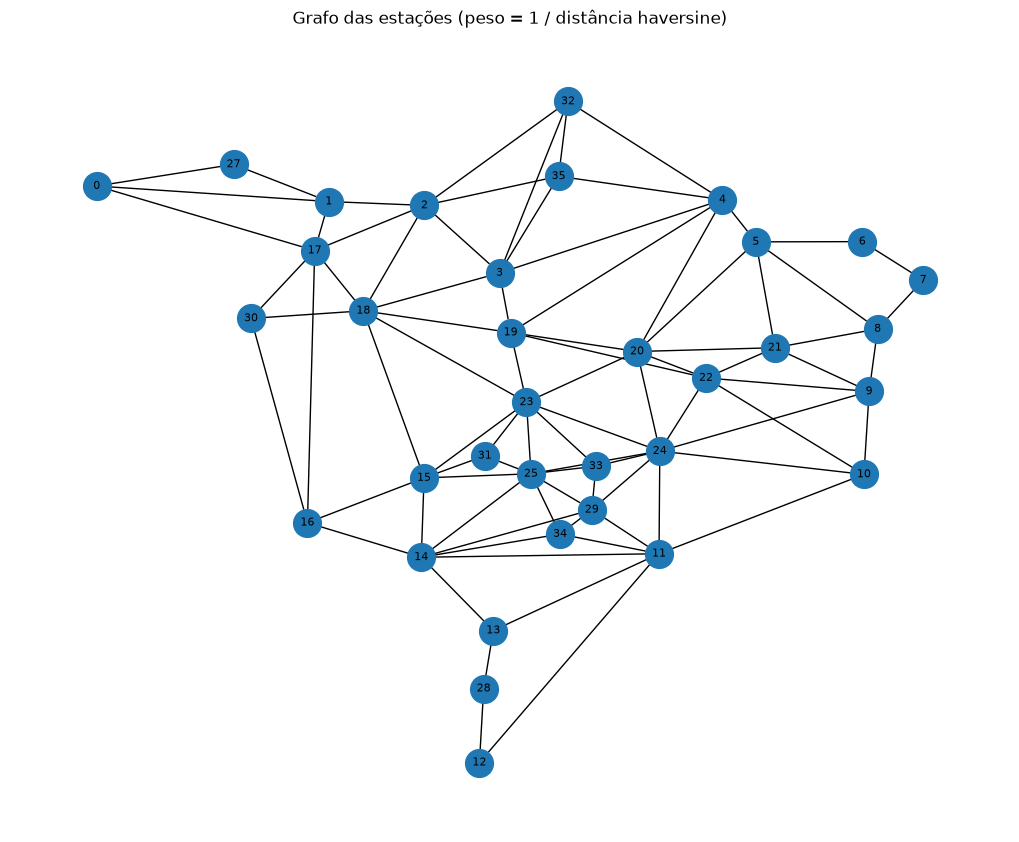

In [3]:
def dms_to_decimal(degrees, minutes, seconds, direction):
    decimal = float(degrees) + float(minutes) / 60 + float(seconds) / 3600
    if str(direction).upper() in ["S", "W", "O"]:
        decimal *= -1
    return decimal


def haversine(lat1, lon1, lat2, lon2):
    R = 6371
    lat1, lon1, lat2, lon2 = map(math.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = math.sin(dlat / 2) ** 2 + math.cos(lat1) * math.cos(lat2) * math.sin(dlon / 2) ** 2
    c = 2 * math.asin(math.sqrt(a))
    return R * c


# Coordenadas de todas as estações
# Formato DMS: (graus, min, seg, direção) para lat e lon
_COORDS_DMS = {
    '1':  (23, 28, 46, 'S', 46, 43, 50, 'W'),
    '2':  (23, 29, 13, 'S', 46, 41, 38, 'W'),
    '3':  (23, 28, 38, 'S', 46, 36, 26, 'W'),
    '4':  (23, 30, 33, 'S', 46, 36, 26, 'W'),
    '5':  (23, 31, 16, 'S', 46, 31, 24, 'W'),
    '6':  (23, 30, 10, 'S', 46, 26, 21, 'W'),
    '7':  (23, 30, 12, 'S', 46, 23, 10, 'W'),
    '8':  (23, 32,  6, 'S', 46, 27, 16, 'W'),
    '9':  (23, 36,  0, 'S', 46, 28, 50, 'W'),
    '10': (23, 40,  4, 'S', 46, 27, 39, 'W'),
    '11': (23, 46, 44, 'S', 46, 31, 42, 'W'),
    '12': (23, 56, 11, 'S', 46, 42, 31, 'W'),
    '13': (23, 40, 58, 'S', 46, 42, 41, 'W'),
    '14': (23, 35, 16, 'S', 46, 43,  0, 'W'),
    '15': (23, 41, 19, 'S', 46, 46, 14, 'W'),
    '16': (23, 37, 58, 'S', 46, 45, 58, 'W'),
    '17': (23, 31, 28, 'S', 46, 42, 21, 'W'),
    '18': (23, 33, 57, 'S', 46, 41, 22, 'W'),
    '19': (23, 32, 46, 'S', 46, 37, 55, 'W'),
    '20': (23, 33, 46, 'S', 46, 35, 52, 'W'),
    '21': (23, 34,  7, 'S', 46, 32, 49, 'W'),
    '22': (23, 35, 33, 'S', 46, 34, 26, 'W'),
    '23': (23, 35, 18, 'S', 46, 38,  4, 'W'),
    '24': (23, 35, 20, 'S', 46, 36, 19, 'W'),
    '25': (23, 39,  8, 'S', 46, 38, 51, 'W'),
    '27': (23, 24, 35, 'S', 46, 44, 34, 'W'),
    '28': (23, 49, 31, 'S', 46, 42, 20, 'W'),
    '29': (23, 40, 30, 'S', 46, 39, 17, 'W'),
    '30': (23, 34,  8, 'S', 46, 43, 45, 'W'),
    '31': (23, 38, 33, 'S', 46, 41, 58, 'W'),
    '32': (23, 24, 44, 'S', 46, 35, 14, 'W'),
    #'34': (23, 29, 46, 'S', 46, 37, 11, 'W'),
    '35': (23, 29, 46, 'S', 46, 37, 11, 'W'),
    '33': (23, 38, 24, 'S', 46, 37, 3, 'W')
}

_COORDS_DEC = {
   # '33': (-23.559765113146554, -46.73399418127595),
    '0':  (-23.43640996621655,  -46.90925768439525),
    '34': (-23.72444, -46.677500),
    '35': (-23.496389, -46.62)
}

COORDS = {}
for node, dms in _COORDS_DMS.items():
    lat = dms_to_decimal(dms[0], dms[1], dms[2], dms[3])
    lon = dms_to_decimal(dms[4], dms[5], dms[6], dms[7])
    COORDS[node] = (lat, lon)
for node, dec in _COORDS_DEC.items():
    COORDS[node] = dec

print(f"Coordenadas carregadas para {len(COORDS)} nós.")
print("Exemplos:")
for n in ['0', '19', '33', '34']:
    if n in COORDS:
        print(f"  Nó {n:>2}: {COORDS[n]}")

nos_sem_coordenada = []
for node in G.nodes():
    node_str = str(node)
    if node_str in COORDS:
        G.nodes[node]['lat'] = COORDS[node_str][0]
        G.nodes[node]['lon'] = COORDS[node_str][1]
    else:
        try:
            G.nodes[node]['lat'] = float(G.nodes[node].get('y', 0))
            G.nodes[node]['lon'] = float(G.nodes[node].get('x', 0))
        except (ValueError, TypeError):
            G.nodes[node]['lat'] = 0.0
            G.nodes[node]['lon'] = 0.0
        nos_sem_coordenada.append(node)

if nos_sem_coordenada:
    print(f"\n[AVISO] Nós sem coordenada explícita (usou fallback x/y): {nos_sem_coordenada}")
else:
    print("\nTodos os nós têm coordenadas explícitas. ✅")

# Peso geográfico das arestas:
# - edge_distance_km: distância haversine em quilômetros
# - inverse_distance_weight: 1 / distância_km
# A GNN usa inverse_distance_weight como edge_weight, ou seja,
# vizinhos mais próximos influenciam mais a mensagem propagada.
DIST_MIN_KM = 0.1

for u, v, k in G.edges(keys=True):
    lat_u = G.nodes[u].get('lat', 0.0)
    lon_u = G.nodes[u].get('lon', 0.0)
    lat_v = G.nodes[v].get('lat', 0.0)
    lon_v = G.nodes[v].get('lon', 0.0)

    dist_km = haversine(lat_u, lon_u, lat_v, lon_v)
    dist_km = max(dist_km, DIST_MIN_KM)
    inv_dist = 1.0 / dist_km

    G.edges[u, v, k]['edge_distance_km'] = dist_km
    G.edges[u, v, k]['inverse_distance_weight'] = inv_dist
    G.edges[u, v, k]['weight'] = inv_dist

pesos = [d['weight'] for _, _, d in G.edges(data=True)]
distancias = [d['edge_distance_km'] for _, _, d in G.edges(data=True)]
print(f"\nPesos geográficos calculados para {len(pesos)} arestas.")
print(f"  Distância mín : {min(distancias):.4f} km")
print(f"  Distância máx : {max(distancias):.4f} km")
print(f"  Peso mín      : {min(pesos):.6f}  (nós mais distantes)")
print(f"  Peso máx      : {max(pesos):.6f}  (nós mais próximos)")
print(f"  Peso médio    : {sum(pesos)/len(pesos):.6f}")

print("\nAmostra de arestas com distância e peso usados no grafo:")
for idx, (u, v, d) in enumerate(G.edges(data=True)):
    print(
        f"  {u} -> {v}: distância = {d['edge_distance_km']:.4f} km | "
        f"peso = {d['weight']:.6f}"
    )
    if idx >= 4:
        break

pos = {n: (float(G.nodes[n]['x']), float(G.nodes[n]['y'])) for n in G.nodes}

plt.figure(figsize=(10, 8))
nx.draw(G, pos, with_labels=True, node_size=400, font_size=8)
plt.title("Grafo das estações (peso = 1 / distância haversine)")
plt.show()
plt.close()


## 3. Caminhos dos dados e carregamento bruto dos CSVs


In [4]:
# Pasta de dados: procura estações_meteorológicas ao lado do notebook (layout do
# repositório); se não achar, cai no caminho local da máquina de desenvolvimento.
import unicodedata as _ud
_CAND_DADOS = [os.getcwd(), os.path.dirname(os.getcwd()),
               "/home/viniz0r/backup_GNN_2026-07-07/completo"]
BASE_METEO = None
for _r in _CAND_DADOS:
    if not os.path.isdir(_r):
        continue
    _hit = next((d for d in os.listdir(_r) if "meteorol" in _ud.normalize("NFC", d)), None)
    if _hit:
        BASE_METEO = os.path.join(_r, _hit)
        break
assert BASE_METEO, "pasta estações_meteorológicas não encontrada"

# Divisão temporal do artigo: treino 2016-2022, validação retida 2023, teste 2024.
# A climatologia (tau, Sigma) usa TODO o histórico 2016-2023 — é estatística de
# referência, não seleção de modelo, e nada de 2024 entra nela.
ANOS_HISTORICO = [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]
ANOS_TREINO = ANOS_HISTORICO[:-1]      # 2016-2022: gradiente
ANO_VAL = 2023                          # validação retida: early stopping / lr
ANO_TESTE = 2024
PATHS_TREINO = {a: f"{BASE_METEO}/meteorologicas_{a}" for a in ANOS_HISTORICO}
PATH_2024 = f"{BASE_METEO}/meteorologicas_{ANO_TESTE}"


def _detectar_sep(caminho_csv: str) -> str:
    with open(caminho_csv, "r", encoding="utf-8", errors="ignore") as f:
        linha = f.readline()
    return ";" if linha.count(";") > linha.count(",") else ","


def _corrigir_cabecalho_csv_cge(caminho_csv: str) -> str:
    with open(caminho_csv, "r", encoding="utf-8", errors="ignore") as f:
        linhas = f.readlines()

    if not linhas:
        return ""

    cabecalho_original = linhas[0]
    cabecalho_corrigido = cabecalho_original.replace("DATA,,", "DATA,", 1)
    cabecalho_corrigido = cabecalho_corrigido.replace("data,,", "data,", 1)
    linhas[0] = cabecalho_corrigido
    return "".join(linhas)


def carregar_estacoes_sem_agregar(path: str) -> pd.DataFrame:
    arquivos = glob.glob(os.path.join(path, "*.csv"))
    estacoes_processadas = []
    arquivos_com_cabecalho_corrigido = 0

    print(f"Iniciando processamento de {len(arquivos)} arquivos em {path}")

    for arq in arquivos:
        id_estacao = os.path.basename(arq).replace(".csv", "")
        sep = _detectar_sep(arq)

        if sep == ",":
            with open(arq, "r", encoding="utf-8", errors="ignore") as f:
                primeira_linha = f.readline()
            if "DATA,," in primeira_linha or "data,," in primeira_linha:
                arquivos_com_cabecalho_corrigido += 1

            conteudo_csv = _corrigir_cabecalho_csv_cge(arq)
            df = pd.read_csv(
                __import__("io").StringIO(conteudo_csv),
                sep=sep,
                engine="python",
                encoding="utf-8",
                on_bad_lines="skip"
            )
        else:
            df = pd.read_csv(
                arq,
                sep=sep,
                engine="python",
                encoding="utf-8",
                on_bad_lines="skip"
            )

        df.columns = [c.strip() for c in df.columns]

        if "DATA" not in df.columns:
            possiveis = [c for c in df.columns if c.lower() in ("data", "datetime", "timestamp")]
            if not possiveis:
                raise ValueError(f"CSV {arq} não tem coluna DATA. Colunas: {df.columns.tolist()}")
            df = df.rename(columns={possiveis[0]: "DATA"})

        # A correção deve acontecer ANTES do read_csv, nunca por reposicionamento
        # posterior das colunas. Se esta coluna aparecer, o cabeçalho ainda veio quebrado.
        if "Unnamed: 2" in df.columns:
            raise ValueError(
                f"Falha ao corrigir cabeçalho do CGE em {os.path.basename(arq)}. "
                "A coluna vazia 'Unnamed: 2' ainda existe após a leitura."
            )

        # A versão 1.6.2 aceitava múltiplos formatos e por isso mantinha janeiro completo.
        # Aqui retomamos esse comportamento para evitar o corte por parsing após 13/01.
        df["DATA"] = pd.to_datetime(df["DATA"], errors="coerce", format="mixed", dayfirst=True)
        df = df.dropna(subset=["DATA"]).set_index("DATA").sort_index()
        df = df[~df.index.duplicated(keep="first")]

        for col in df.columns:
            if df[col].dtype == "object":
                df[col] = (
                    df[col].astype(str)
                    .str.replace(",", ".", regex=False)
                    .str.strip()
                )
                try:
                    df[col] = pd.to_numeric(df[col], errors="ignore")
                except Exception:
                    pass

        df["station_id"] = id_estacao
        estacoes_processadas.append(df)

    if not estacoes_processadas:
        raise ValueError(f"Nenhum CSV encontrado em {path}")

    print(f"Arquivos com cabeçalho CGE corrigido em {path}: {arquivos_com_cabecalho_corrigido}")

    df_final = pd.concat(estacoes_processadas).sort_index()
    df_final.index.name = "DATA"
    return df_final


dfs_treino = {a: carregar_estacoes_sem_agregar(p) for a, p in PATHS_TREINO.items()}
df_2024 = carregar_estacoes_sem_agregar(PATH_2024)

for a, dfa in dfs_treino.items():
    print(f"Total de registros {a}: {len(dfa)}")
print(f"Total de registros {ANO_TESTE}: {len(df_2024)}")
print(f"Período {ANO_TESTE} carregado:", df_2024.index.min(), "até", df_2024.index.max())


Iniciando processamento de 32 arquivos em /home/viniz0r/backup_GNN_2026-07-07/completo/estações_meteorológicas/meteorologicas_2016


Arquivos com cabeçalho CGE corrigido em /home/viniz0r/backup_GNN_2026-07-07/completo/estações_meteorológicas/meteorologicas_2016: 32


Iniciando processamento de 31 arquivos em /home/viniz0r/backup_GNN_2026-07-07/completo/estações_meteorológicas/meteorologicas_2017


Arquivos com cabeçalho CGE corrigido em /home/viniz0r/backup_GNN_2026-07-07/completo/estações_meteorológicas/meteorologicas_2017: 31


Iniciando processamento de 32 arquivos em /home/viniz0r/backup_GNN_2026-07-07/completo/estações_meteorológicas/meteorologicas_2018


...

Iniciando processamento de 32 arquivos em /home/viniz0r/backup_GNN_2026-07-07/completo/estações_meteorológicas/meteorologicas_2023


Arquivos com cabeçalho CGE corrigido em /home/viniz0r/backup_GNN_2026-07-07/completo/estações_meteorológicas/meteorologicas_2023: 32


Iniciando processamento de 32 arquivos em /home/viniz0r/backup_GNN_2026-07-07/completo/estações_meteorológicas/meteorologicas_2024


Arquivos com cabeçalho CGE corrigido em /home/viniz0r/backup_GNN_2026-07-07/completo/estações_meteorológicas/meteorologicas_2024: 32


Total de registros 2016: 1684726
Total de registros 2017: 1679608
Total de registros 2018: 1675138
Total de registros 2019: 1670593
Total de registros 2020: 1717264
Total de registros 2021: 1735006
Total de registros 2022: 1724155
Total de registros 2023: 1730836
Total de registros 2024: 1676382
Período 2024 carregado: 2024-01-01 00:00:00 até 2024-12-31 23:50:00


## 4. Montagem robusta do tensor `[tempo, nós, atributos]` com diagnóstico e imputação espacial dos nós cegos


In [5]:
def normalizar_nome(s):
    s = str(s).lower().strip()
    s = unicodedata.normalize("NFKD", s).encode("ASCII", "ignore").decode("ASCII")
    s = re.sub(r"[^a-z0-9]+", "_", s)
    s = re.sub(r"_+", "_", s).strip("_")
    return s


MAPA_FIXO_CSV = {
    "p503": "19",
    "p510": "3",
    "p846": "14",
    "p1000857": "13",
    "p1000880": "0",
}

NOS_CEGOS_DEFAULT = {"33", "34", "35"}

_STOPWORDS_MATCH = {
    "do", "da", "de", "dos", "das", "e", "o", "a", "os", "as", "em", "no", "na",
    "sp", "cge", "dados", "pmsp", "comdec", "municipal", "meteorologica",
    "estacao", "esta", "paco", "rinco",
    "fo", "la", "sa", "cl", "mo", "mp", "iq", "vm", "pr", "pa", "bt", "pi",
    "ip", "sm", "mb", "af", "mg", "ad", "ja", "cs", "jt", "pe", "it", "pj", "vp",
}


def _palavras_relevantes(s):
    norm = normalizar_nome(s)
    tokens = norm.split("_")
    tokens = [t for t in tokens if not re.match(r"^p\d+$", t)]
    return [t for t in tokens if len(t) >= 3 and t not in _STOPWORDS_MATCH]


def _score_tokens(tokens_csv, tokens_label):
    if not tokens_label:
        return 0.0
    matches = sum(
        1 for pl in tokens_label
        if any(pl in pc or pc in pl for pc in tokens_csv)
    )
    return matches / len(tokens_label)


def construir_indice_mapeamento_nos(G):
    indice = []
    for node in G.nodes():
        label = G.nodes[node].get("label", "")
        indice.append({
            "node_id": str(node),
            "label": label,
            "tokens_label": _palavras_relevantes(label),
        })
    return indice


INDICE_NOS_PARA_MATCH = construir_indice_mapeamento_nos(G)


def encontrar_no_correspondente(nome_arquivo, indice_nos=INDICE_NOS_PARA_MATCH):
    stem_norm = normalizar_nome(nome_arquivo)

    for chave, node_id in MAPA_FIXO_CSV.items():
        if chave in stem_norm:
            return node_id

    tokens_csv = _palavras_relevantes(nome_arquivo)
    melhor_no = None
    melhor_score = 0.0

    for item in indice_nos:
        score = _score_tokens(tokens_csv, item["tokens_label"])
        if score > melhor_score:
            melhor_score = score
            melhor_no = item["node_id"]

    if melhor_score >= 0.5:
        return melhor_no

    return None


def mapear_estacoes_para_nos(station_ids_unicos):
    mapeamento = {}
    for station_id in sorted(set(map(str, station_ids_unicos))):
        mapeamento[station_id] = encontrar_no_correspondente(station_id)
    return mapeamento


def imprimir_relacao_no_csv(G, mapa_station_para_no, nome_conjunto, nos_cegos=NOS_CEGOS_DEFAULT):
    no_para_stations = {}
    for station_id, node_id in mapa_station_para_no.items():
        if node_id is None:
            continue
        no_para_stations.setdefault(str(node_id), []).append(station_id)

    print(f"\n[{nome_conjunto}] CSV associado a cada nó para treino:")
    for node in map(str, G.nodes()):
        label = G.nodes[node].get("label", "")
        csvs = sorted(no_para_stations.get(node, []))
        if csvs:
            print(f"  Nó {node:>2} ({label}): {', '.join(f'{csv}.csv' for csv in csvs)}")
        elif node in set(map(str, nos_cegos)):
            print(f"  Nó {node:>2} ({label}): nó cego -> sem CSV próprio, entrada via média simples dos vizinhos")
        else:
            print(f"  Nó {node:>2} ({label}): sem CSV associado")

    estacoes_sem_no = sorted([station for station, node in mapa_station_para_no.items() if node is None])
    if estacoes_sem_no:
        print(f"\n[{nome_conjunto}] Estações sem correspondência no grafo:")
        for est in estacoes_sem_no:
            print(f"  - {est}.csv")


def _primeira_coluna_existente(df: pd.DataFrame, candidatos: list[str]) -> str:
    normalizadas = {normalizar_nome(c): c for c in df.columns}
    for c in candidatos:
        if c in df.columns:
            return c
    for c in candidatos:
        c_norm = normalizar_nome(c)
        if c_norm in normalizadas:
            return normalizadas[c_norm]
    raise KeyError(f"Nenhuma das colunas {candidatos} existe. Colunas disponíveis: {df.columns.tolist()}")


def _vizinhos_do_no(G, node):
    node = str(node)
    vizinhos = []

    for viz in G.neighbors(node):
        vizinhos.append(str(viz))

    if len(vizinhos) == 0:
        return []

    return vizinhos


def forcar_nos_cegos_sem_dados(df_pivot, nos_cegos, features):
    for feat in features:
        for no in map(str, nos_cegos):
            if no in df_pivot[feat].columns:
                df_pivot[(feat, no)] = np.nan
    return df_pivot


def imputar_nos_cegos_por_vizinhos(df_pivot, G, nos_cegos, features):
    for feat in features:
        bloco = df_pivot[feat].copy()

        for no in map(str, nos_cegos):
            if no not in bloco.columns:
                continue

            if not bloco[no].isna().all():
                continue

            vizinhos = [v for v in _vizinhos_do_no(G, no) if v in bloco.columns]

            if len(vizinhos) == 0:
                print(f"[IMPUTAÇÃO] Nó {no} sem vizinhos válidos para {feat}.")
                continue

            mat = bloco[vizinhos].to_numpy(dtype=float)
            imputado = np.full(shape=(mat.shape[0],), fill_value=np.nan, dtype=float)

            for t in range(mat.shape[0]):
                linha = mat[t]
                mask = ~np.isnan(linha)
                if mask.sum() == 0:
                    continue

                imputado[t] = float(np.mean(linha[mask]))

            bloco[no] = imputado
            print(f"[IMPUTAÇÃO] Nó cego {no} preenchido por média simples dos vizinhos em {feat}.")

        df_pivot[feat] = bloco

    return df_pivot


def inicializar_nos_cegos_zero(df_pivot, nos_cegos, features):
    """Inicializa os nós cegos com 0.0 (entrada do Feature Propagation)."""
    for feat in features:
        bloco = df_pivot[feat]
        for no in map(str, nos_cegos):
            if no in bloco.columns:
                df_pivot[(feat, no)] = 0.0
    return df_pivot


def preparar_dataset_final_v6(
    df_input: pd.DataFrame,
    G,
    nome_conjunto="dataset",
    nos_cegos=NOS_CEGOS_DEFAULT
):
    df_fix = df_input.copy()

    def _selecionar_coluna_temperatura(df: pd.DataFrame) -> str:
        candidatos = [
            "Temp(oC)",
            "Temp(°C)",
            "Temperatura(°C)",
            "Sens. Térmica(°C)",
            "Sens. Termica(°C)",
        ]
        normalizadas = {normalizar_nome(c): c for c in df.columns}
        disponiveis = []
        for cand in candidatos:
            if cand in df.columns:
                col = cand
            else:
                col = normalizadas.get(normalizar_nome(cand))
            if col is None:
                continue
            serie = pd.to_numeric(df[col], errors="coerce")
            disponiveis.append((col, int(serie.notna().sum())))

        if not disponiveis:
            raise KeyError("Nenhuma coluna de temperatura encontrada.")

        disponiveis.sort(key=lambda item: (-item[1], candidatos.index(item[0]) if item[0] in candidatos else 999))
        col_escolhida = disponiveis[0][0]
        if normalizar_nome(col_escolhida).startswith("sens_termica"):
            print(f"[AVISO] Usando sensação térmica como fallback de temperatura: {col_escolhida}")
        return col_escolhida

    col_plu = _primeira_coluna_existente(df_fix, ["PLU(mm)", "PLU (mm)", "PLU_mm", "pluviosidade(mm)", "Pluviosidade(mm)"])
    col_vel = _primeira_coluna_existente(df_fix, ["Vel.VT(m/s)", "VEL(m/s)", "VEL", "Velocidade(m/s)"])
    col_temp = _selecionar_coluna_temperatura(df_fix)

    col_umid = None
    for cand in ["Umid.Rel(%)", "Umid Rel(%)", "Umidade(%)", "UMID(%)", "Umidade Relativa(%)"]:
        try:
            col_umid = _primeira_coluna_existente(df_fix, [cand])
            break
        except KeyError:
            continue

    print(f"\n[{nome_conjunto}] Colunas escolhidas:")
    print("PLU  ->", col_plu)
    print("TEMP ->", col_temp)
    print("UMID ->", col_umid if col_umid is not None else "não encontrada")
    print("VEL  ->", col_vel)

    df_fix["PLU_real"] = pd.to_numeric(df_fix[col_plu], errors="coerce")
    df_fix["VEL_real"] = pd.to_numeric(df_fix[col_vel], errors="coerce")
    df_fix["TEMP_real"] = pd.to_numeric(df_fix[col_temp], errors="coerce")
    df_fix["UMID_real"] = pd.to_numeric(df_fix[col_umid], errors="coerce") if col_umid is not None else np.nan

    station_ids_unicos = df_fix["station_id"].astype(str).dropna().unique().tolist()
    mapa_station_para_no = mapear_estacoes_para_nos(station_ids_unicos)
    df_fix["node_id"] = df_fix["station_id"].astype(str).map(mapa_station_para_no)

    imprimir_relacao_no_csv(G, mapa_station_para_no, nome_conjunto, nos_cegos=nos_cegos)

    print(f"\n[{nome_conjunto}] Total de linhas antes do dropna: {len(df_fix)}")
    sem_no = df_fix["node_id"].isna().sum()
    print(f"[{nome_conjunto}] Linhas sem node_id: {sem_no}")

    df_fix = df_fix.dropna(subset=["node_id"]).copy()
    df_fix["node_id"] = df_fix["node_id"].astype(str)

    features = ["PLU_real", "TEMP_real", "UMID_real", "VEL_real"]
    nodes_lista = list(map(str, G.nodes()))

    df_pivot = (
        df_fix.reset_index()
        .pivot_table(index="DATA", columns="node_id", values=features, aggfunc="mean")
        .sort_index()
    )

    # Reamostra para uma grade genuina de 10 minutos. Os ticks :05 vem de
    # linhas vazias do datalogger da estacao de Butanta e nao carregam medicao;
    # a agregacao por media (ignorando NaN) preserva apenas a leitura real de
    # cada bloco de 10 min e descarta os instantes sinteticos, evitando alvos
    # interpolados triviais na previsao.
    df_pivot = df_pivot.resample("10min").mean()

    df_pivot = df_pivot.reindex(
        columns=pd.MultiIndex.from_product([features, nodes_lista]),
        fill_value=np.nan
    )

    # Mantém explicitamente 33, 34 e 35 como nós cegos no experimento,
    # mesmo que no futuro alguma fonte auxiliar apareça para eles.
    df_pivot = forcar_nos_cegos_sem_dados(df_pivot, nos_cegos=nos_cegos, features=features)

    for feat in features:
        bloco = df_pivot[feat]
        nos_vazios = bloco.columns[bloco.isna().all()].tolist()
        if nos_vazios:
            print(f"[ALERTA][{nome_conjunto}] Nós totalmente vazios para {feat}: {nos_vazios}")

    df_pivot = df_pivot.interpolate(method="time", limit_direction="both")
    # MUDANÇA 2: os nós cegos NÃO são mais preenchidos por média simples dos
    # vizinhos aqui. Eles são inicializados em 0.0 e preenchidos depois, fora
    # desta função, pelo Feature Propagation iterativo (Rossi et al., 2022),
    # que usa a estrutura completa do grafo e restaura as âncoras a cada passo.
    df_pivot = inicializar_nos_cegos_zero(
        df_pivot=df_pivot,
        nos_cegos=nos_cegos,
        features=features
    )
    df_pivot = df_pivot.ffill().bfill()

    for feat in features:
        if feat == "PLU_real":
            df_pivot[feat] = df_pivot[feat].fillna(0.0)
        else:
            media_global = np.nanmean(df_pivot[feat].to_numpy(dtype=float))
            if np.isnan(media_global):
                media_global = 0.0
            df_pivot[feat] = df_pivot[feat].fillna(float(media_global))

    data_3d = (
        df_pivot.values
        .reshape(len(df_pivot), len(features), len(nodes_lista))
        .transpose(0, 2, 1)
    )

    X = torch.tensor(data_3d, dtype=torch.float32).to(DEVICE)
    return X, df_pivot.index, df_fix, df_pivot, mapa_station_para_no


# Processa cada ano de treino separadamente (grade de 10 min e interpolação
# ficam contidas dentro de cada ano, sem vazamento entre anos).
Xraw_treino = {}
ts_treino = {}
for a, dfa in dfs_treino.items():
    Xa, tsa, _, _, _ = preparar_dataset_final_v6(dfa, G, nome_conjunto=str(a))
    Xraw_treino[a] = Xa
    ts_treino[a] = tsa

X_2024, timestamps_2024, df_fix_2024, df_pivot_2024, mapa_csv_no_2024 = preparar_dataset_final_v6(df_2024, G, nome_conjunto="2024")

print("\nShapes finais (pré-FP):")
for a in ANOS_HISTORICO:
    print(f"  X_{a}:", tuple(Xraw_treino[a].shape))
print("  X_2024:", tuple(X_2024.shape))



[2016] Colunas escolhidas:
PLU  -> PLU(mm)
TEMP -> Temp(oC)
UMID -> Umid.Rel.(%)
VEL  -> Vel.VT(m/s)



[2016] CSV associado a cada nó para treino:
  Nó  0 (Santana do Parnaiba): 2016_cge_P1000880_Santana_do_Parna_ba.csv
  Nó  1 (Pirituba): 2016_cge_P515_Pirituba__PMSP_PJ_01_.csv
  Nó  2 (Freguesia do Ó  ): 2016_cge_P509_Freguesia_do____PMSP_FO_01_.csv
  Nó  3 (Santana / Tucuruvi): 2016_cge_P510_Santana_Tucuruvi___COMDEC__PMSP_ST_01_.csv
  Nó  4 (Vila Maria / Guilherme): 2016_cge_P540_Vila_Maria___Vila_Guilherme__PMSP_MG_01_.csv
  Nó  5 (Penha): 2016_cge_P1000887_Penha___Rinc_o__PMSP_PE_01_.csv
  Nó  6 (S. Miguel Paulista): 2016_cge_P1000862_S_o_Miguel_Paulista__PMSP_MP_01_.csv
  Nó  7 (Itaim Paulista): 2016_cge_P1000882_Itaim_Paulista__PMSP_IT_01_.csv
  Nó  8 (Itaquera): 2016_cge_P1000864_Itaquera__PMSP_IQ_02_.csv
  Nó  9 (São Mateus): 2016_cge_P1000844_S_o_Mateus__PMSP_SM_05_.csv
  Nó 10 (Mauá - Paço Municipal): 2016_cge_P1000876_Mau____Pa_o_Municipal.csv
  Nó 11 (Riacho Grande): 2016_cge_P400_Riacho_Grande.csv
  Nó 12 (Marsilac - Palheiros): 2016_cge_P1000300_Esta__o_Me

[ALERTA][2016] Nós totalmente vazios para PLU_real: ['14', '33', '34', '35']
[ALERTA][2016] Nós totalmente vazios para TEMP_real: ['12', '14', '33', '34', '35']
[ALERTA][2016] Nós totalmente vazios para UMID_real: ['12', '14', '33', '34', '35']
[ALERTA][2016] Nós totalmente vazios para VEL_real: ['0', '1', '2', '4', '6', '8', '12', '13', '14', '16', '18', '20', '21', '22', '25', '29', '31', '33', '34', '35']



[2017] Colunas escolhidas:
PLU  -> PLU(mm)
TEMP -> Temp(oC)
UMID -> Umid.Rel.(%)
VEL  -> Vel.VT(m/s)



[2017] CSV associado a cada nó para treino:
  Nó  0 (Santana do Parnaiba): _P1000880_Santana_do_Parna_ba.csv
  Nó  1 (Pirituba): _P515_Pirituba__PMSP_PJ_01_.csv
  Nó  2 (Freguesia do Ó  ): _P509_Freguesia_do____PMSP_FO_01_.csv
  Nó  3 (Santana / Tucuruvi): _P510_Santana_Tucuruvi___COMDEC__PMSP_ST_01_.csv
  Nó  4 (Vila Maria / Guilherme): _P540_Vila_Maria___Vila_Guilherme__PMSP_MG_01_.csv
  Nó  5 (Penha): _P1000887_Penha___Rinc_o__PMSP_PE_01_.csv
  Nó  6 (S. Miguel Paulista): _P1000862_S_o_Miguel_Paulista__PMSP_MP_01_.csv
  Nó  7 (Itaim Paulista): _P1000882_Itaim_Paulista__PMSP_IT_01_.csv
  Nó  8 (Itaquera): _P1000864_Itaquera__PMSP_IQ_02_.csv
  Nó  9 (São Mateus): _P1000844_S_o_Mateus__PMSP_SM_05_.csv
  Nó 10 (Mauá - Paço Municipal): _P1000876_Mau____Pa_o_Municipal.csv
  Nó 11 (Riacho Grande): _P400_Riacho_Grande.csv
  Nó 12 (Marsilac - Palheiros): sem CSV associado
  Nó 13 (Capela do Socorro): _P1000857_Capela_do_Socorro__PMSP_CS_01_.csv
  Nó 14 (Capela do Socorro - S

...

[ALERTA][2023] Nós totalmente vazios para PLU_real: ['33', '34', '35']
[ALERTA][2023] Nós totalmente vazios para TEMP_real: ['33', '34', '35']
[ALERTA][2023] Nós totalmente vazios para UMID_real: ['33', '34', '35']
[ALERTA][2023] Nós totalmente vazios para VEL_real: ['1', '4', '6', '8', '18', '20', '21', '25', '31', '33', '34', '35']



[2024] Colunas escolhidas:
PLU  -> PLU(mm)
TEMP -> Temp(oC)
UMID -> Umid.Rel.(%)
VEL  -> Vel.VT(m/s)



[2024] CSV associado a cada nó para treino:
  Nó  0 (Santana do Parnaiba): primeiro___P1000880_Santana_de_Parna_ba___Ponte_dos_Romeiros.csv
  Nó  1 (Pirituba): primeiro___P515_Pirituba_Jaragu____Ch_cara_Inglesa__PMSP_PJ_01_.csv
  Nó  2 (Freguesia do Ó  ): primeiro___P509_Freguesia_do_____Vila_Nova_Cachoeirinha__PMSP_FO_01_.csv
  Nó  3 (Santana / Tucuruvi): primeiro___P510_Santana___Carandir___PMSP_ST_01_.csv
  Nó  4 (Vila Maria / Guilherme): primeiro___P540_Vila_Maria_Vila_Guilherme___Vila_Medeiros__PMSP_MG_01_.csv
  Nó  5 (Penha): primeiro___P1000887_Penha___Rinc_o__PMSP_PE_01_.csv
  Nó  6 (S. Miguel Paulista): primeiro___P1000862_S_o_Miguel_Paulista___Vila_Jacu___PMSP_MP_01_.csv
  Nó  7 (Itaim Paulista): primeiro___P1000882_Itaim_Paulista___Vila_Curu_a__PMSP_IT_01_.csv
  Nó  8 (Itaquera): primeiro___P1000864_Itaquera___Vila_Carmosina__PMSP_IQ_02_.csv
  Nó  9 (São Mateus): primeiro___P1000844_S_o_Mateus___Parque_do_Carmo__PMSP_SM_05__INATIVO.csv
  Nó 10 (Mauá - Paço Munic

[ALERTA][2024] Nós totalmente vazios para PLU_real: ['33', '34', '35']
[ALERTA][2024] Nós totalmente vazios para TEMP_real: ['33', '34', '35']
[ALERTA][2024] Nós totalmente vazios para UMID_real: ['33', '34', '35']
[ALERTA][2024] Nós totalmente vazios para VEL_real: ['1', '4', '6', '8', '18', '20', '21', '25', '31', '33', '34', '35']



Shapes finais (pré-FP):
  X_2016: (52705, 35, 4)
  X_2017: (52561, 35, 4)
  X_2018: (52561, 35, 4)
  X_2019: (52561, 35, 4)
  X_2020: (52705, 35, 4)
  X_2021: (52561, 35, 4)
  X_2022: (52561, 35, 4)
  X_2023: (52561, 35, 4)
  X_2024: (52704, 35, 4)


## 6. Grafo em PyTorch Geometric e teste rápido


## Mudança 1 — Normalização das arestas por nó de destino

**Problema da versão anterior (0.7.5):** o `edge_weight` era normalizado por
min-max global (`(w - w.min()) / (w.max() - w.min())`). Uma única aresta muito
curta (peso enorme) comprimia todos os outros pesos para perto de zero,
dominando a agregação.

**Correção:** normalização por **nó de destino**, garantindo que a soma dos
pesos das arestas que chegam a cada nó seja 1:

$$\tilde{w}_{ij} = \frac{w_{ij}}{\sum_{k \in N(j)} w_{kj}}$$

Em PyG isso corresponde à normalização $D^{-1} A$ (por linha do nó destino).
Também definimos a versão **simétrica** $D^{-1/2} A D^{-1/2}$, usada pelo
Feature Propagation (Mudança 2).


In [6]:
def normalize_edge_weights_by_destination(edge_index, edge_weight, num_nodes):
    """Normaliza w_ij dividindo pela soma dos pesos que chegam ao nó destino j.

    Equivale a D^{-1} A (normalização por linha do nó de destino), garantindo
    que sum_{k in N(j)} w_kj = 1 para todo j com pelo menos um vizinho.
    edge_index: [2, E] (linha 0 = origem i, linha 1 = destino j)
    """
    dst = edge_index[1]
    deg = scatter(edge_weight, dst, dim=0, dim_size=num_nodes, reduce="sum")
    deg = deg.clamp(min=1e-12)
    return edge_weight / deg[dst]


def normalize_edge_weights_symmetric(edge_index, edge_weight, num_nodes):
    """Normalização simétrica D^{-1/2} A D^{-1/2}, usada no Feature Propagation."""
    src, dst = edge_index[0], edge_index[1]
    deg = scatter(edge_weight, dst, dim=0, dim_size=num_nodes, reduce="sum")
    deg = deg.clamp(min=1e-12)
    deg_inv_sqrt = deg.pow(-0.5)
    return deg_inv_sqrt[src] * edge_weight * deg_inv_sqrt[dst]


In [7]:
# PyTorch Geometric trabalha com edge_index.
# Se o grafo for não-direcionado, duplicamos cada aresta nos dois sentidos.
nodes_lista = list(G.nodes())
node_to_idx = {node: i for i, node in enumerate(nodes_lista)}

edges_src = []
edges_dst = []
edges_weight_raw = []
edges_distance_km = []

for u, v, attrs in G.edges(data=True):
    i = node_to_idx[u]
    j = node_to_idx[v]
    dist_km = float(attrs.get("edge_distance_km", 0.0))
    raw_weight = float(attrs.get("inverse_distance_weight", attrs.get("weight", 1.0)))

    edges_src.append(i)
    edges_dst.append(j)
    edges_weight_raw.append(raw_weight)
    edges_distance_km.append(dist_km)

    if not G.is_directed():
        edges_src.append(j)
        edges_dst.append(i)
        edges_weight_raw.append(raw_weight)
        edges_distance_km.append(dist_km)

edge_index = torch.tensor([edges_src, edges_dst], dtype=torch.long)
edge_weight_raw = torch.tensor(edges_weight_raw, dtype=torch.float32)
edge_distance_km = torch.tensor(edges_distance_km, dtype=torch.float32)

# MUDANÇA 1: normalização por nó de destino (D^{-1} A), no lugar do antigo
# min-max global. Garante que a soma dos pesos dos vizinhos de cada nó seja 1.
edge_weight = normalize_edge_weights_by_destination(
    edge_index, edge_weight_raw, num_nodes=len(nodes_lista)
)

# Versão simétrica D^{-1/2} A D^{-1/2}, reservada ao Feature Propagation (Mudança 2).
edge_weight_sym = normalize_edge_weights_symmetric(
    edge_index, edge_weight_raw, num_nodes=len(nodes_lista)
)

g_pyg = Data(
    edge_index=edge_index,
    edge_weight=edge_weight,
    edge_weight_sym=edge_weight_sym,
    edge_weight_raw=edge_weight_raw,
    edge_distance_km=edge_distance_km,
    num_nodes=len(nodes_lista)
).to(DEVICE)

print(f"Grafo PyG: {g_pyg.num_nodes} nós, {g_pyg.edge_index.size(1)} arestas direcionadas")
print("Pesos usados na GNN:")
print(
    f"  edge_distance_km - mín: {g_pyg.edge_distance_km.min():.4f} | "
    f"máx: {g_pyg.edge_distance_km.max():.4f}"
)
print(
    f"  edge_weight_raw (1/distância) - mín: {g_pyg.edge_weight_raw.min():.6f} | "
    f"máx: {g_pyg.edge_weight_raw.max():.6f}"
)
print(
    f"  edge_weight normalizado - mín: {g_pyg.edge_weight.min():.4f} | "
    f"máx: {g_pyg.edge_weight.max():.4f} | "
    f"médio: {g_pyg.edge_weight.mean():.4f}"
)

print("\nAmostra PyG: distância geográfica versus peso efetivo")
for idx in range(min(5, g_pyg.edge_index.size(1))):
    src_idx = int(g_pyg.edge_index[0, idx].item())
    dst_idx = int(g_pyg.edge_index[1, idx].item())
    src_node = nodes_lista[src_idx]
    dst_node = nodes_lista[dst_idx]
    print(
        f"  {src_node} -> {dst_node}: distância = {g_pyg.edge_distance_km[idx].item():.4f} km | "
        f"peso bruto = {g_pyg.edge_weight_raw[idx].item():.6f} | "
        f"peso normalizado = {g_pyg.edge_weight[idx].item():.6f}"
    )


Grafo PyG: 35 nós, 170 arestas direcionadas
Pesos usados na GNN:
  edge_distance_km - mín: 1.9278 | máx: 28.6249
  edge_weight_raw (1/distância) - mín: 0.034935 | máx: 0.518727
  edge_weight normalizado - mín: 0.0287 | máx: 0.6871 | médio: 0.2059

Amostra PyG: distância geográfica versus peso efetivo
  0 -> 1: distância = 18.8461 km | peso bruto = 0.053061 | peso normalizado = 0.085597
  1 -> 0: distância = 18.8461 km | peso bruto = 0.053061 | peso normalizado = 0.343115
  0 -> 17: distância = 22.9402 km | peso bruto = 0.043592 | peso normalizado = 0.047756
  17 -> 0: distância = 22.9402 km | peso bruto = 0.043592 | peso normalizado = 0.281881
  0 -> 27: distância = 17.2435 km | peso bruto = 0.057993 | peso normalizado = 0.312895


## Mudança 2 — Feature Propagation iterativa nos nós cegos

Substitui a antiga imputação por média simples dos vizinhos (equivalente a uma
única iteração de difusão, sem restauração de âncoras).

Baseado em **Rossi et al., *On the Unreasonable Effectiveness of Feature
Propagation in Learning on Graphs With Missing Node Features*, ICLR 2022**.
O algoritmo minimiza a energia de Dirichlet
$\ell(x, G) = \tfrac{1}{2} x^\top \Delta x = \tfrac{1}{2} \sum_{ij}\tilde a_{ij}(x_i - x_j)^2$
propagando as features pela adjacência simétrica normalizada
$\tilde A = D^{-1/2} A D^{-1/2}$ e **restaurando os valores reais das âncoras a
cada iteração** (passo crítico). Usamos **40 iterações**.

Aplicamos a propagação independentemente a cada timestep dos tensores
`X_2023` e `X_2024`, preenchendo apenas os nós cegos (33, 34, 35); os nós CGE
(âncoras) permanecem com seus valores observados.


In [8]:
def feature_propagation_batch(X, edge_index, edge_weight, known_mask, num_iter=40):
    """Feature Propagation vetorizado sobre [T, N, F] (Rossi et al., ICLR 2022).

    Processa todos os timesteps em paralelo (sem loop por t).
    A cada iteração:
      1. X[:, dst, :] = sum_over_src( edge_weight * X[:, src, :] )   (difusão)
      2. X[:, known_mask, :] = X_known                                 (restaura âncoras)
    """
    X = X.clone().float()
    X_known = X[:, known_mask, :].clone()
    src, dst = edge_index[0], edge_index[1]
    ew = edge_weight.float().view(1, -1, 1)  # [1, E, 1] para broadcast
    T, N, F = X.shape

    for _ in range(num_iter):
        # [T, E, F] <- pesos dos vizinhos ponderados
        msgs = X[:, src, :] * ew                         # [T, E, F]
        # scatter: acumula msgs nos nós destino
        X_new = torch.zeros(T, N, F, device=X.device)
        X_new.index_add_(1, dst, msgs)
        X_new[:, known_mask, :] = X_known                # restaura âncoras
        X = X_new

    return X


def imputacao_media_vizinhos_batch(X, edge_index, num_nodes, blind_idx):
    """Baseline vetorizado: média simples dos vizinhos (1 passo), shape [T, N, F]."""
    X = X.clone().float()
    src, dst = edge_index[0], edge_index[1]
    T, N, F = X.shape
    # Contagem de vizinhos por nó destino
    cont = torch.zeros(N, device=X.device)
    cont.index_add_(0, dst, torch.ones(dst.size(0), device=X.device))
    cont = cont.clamp(min=1.0).view(1, N, 1)             # [1, N, 1]
    # Somar features dos vizinhos
    soma = torch.zeros(T, N, F, device=X.device)
    soma.index_add_(1, dst, X[:, src, :])
    media = soma / cont                                    # [T, N, F]
    # Aplicar apenas nos nós cegos
    blind_t = torch.tensor(blind_idx, device=X.device)
    X[:, blind_t, :] = media[:, blind_t, :]
    return X


# Conjunto de nós cegos (sem CSV próprio).
NOS_SEM_DADOS = {"33", "34", "35"}
known_mask = torch.tensor(
    [str(n) not in NOS_SEM_DADOS for n in nodes_lista],
    dtype=torch.bool, device=DEVICE
)
blind_idx = [i for i, n in enumerate(nodes_lista) if str(n) in NOS_SEM_DADOS]
print(f"Âncoras (known_mask=True): {int(known_mask.sum())} | "
      f"Nós cegos (False): {int((~known_mask).sum())} -> {sorted(NOS_SEM_DADOS)}")

FP_ITER = 40
ei  = g_pyg.edge_index.to(DEVICE)
ew_sym = g_pyg.edge_weight_sym.to(DEVICE)
# CORRECAO FP: usar normalizacao por linha D^{-1}A (random-walk) no Feature
# Propagation. A simetrica D^{-1/2}AD^{-1/2} encolhe o valor de nos cegos
# fracamente conectados em direcao a zero (undershoot); a row-stochastic da
# combinacao convexa dos vizinhos, mantendo a estimativa no intervalo fisico.
ew_rw = g_pyg.edge_weight.to(DEVICE)

# Baseline (1 passo, média simples) do ANO DE TESTE — salvo ANTES do FP.
print("Calculando baseline (média simples dos vizinhos) para 2024...")
X_2024_baseline = imputacao_media_vizinhos_batch(X_2024, ei, len(nodes_lista), blind_idx)

# Feature Propagation em cada ano de treino e no ano de teste.
X_treino = {}
for a in ANOS_HISTORICO:
    print(f"Aplicando Feature Propagation ({FP_ITER} it.) em X_{a}...")
    X_treino[a] = feature_propagation_batch(Xraw_treino[a], ei, ew_rw, known_mask, num_iter=FP_ITER)
print(f"Aplicando Feature Propagation ({FP_ITER} it.) em X_2024...")
X_2024 = feature_propagation_batch(X_2024, ei, ew_rw, known_mask, num_iter=FP_ITER)
del Xraw_treino  # libera os tensores pré-FP

# Tensor histórico (todos os anos de treino) para a climatologia (limiares e covariância).
X_hist = torch.cat([X_treino[a] for a in ANOS_HISTORICO], dim=0)
timestamps_hist = np.concatenate([np.asarray(ts_treino[a]) for a in ANOS_HISTORICO])

print("Feature Propagation concluído.")
print("X_hist (treino concatenado):", tuple(X_hist.shape), "| X_2024:", tuple(X_2024.shape))
for j in blind_idx:
    print(f"  Nó cego {nodes_lista[j]}: PLU médio FP (2024) = {X_2024[:, j, 0].mean():.4f} | "
          f"Temp média FP (2024) = {X_2024[:, j, 1].mean():.4f}")


Âncoras (known_mask=True): 32 | Nós cegos (False): 3 -> ['33', '34', '35']
Calculando baseline (média simples dos vizinhos) para 2024...
Aplicando Feature Propagation (40 it.) em X_2016...


Aplicando Feature Propagation (40 it.) em X_2017...


Aplicando Feature Propagation (40 it.) em X_2018...


Aplicando Feature Propagation (40 it.) em X_2019...


Aplicando Feature Propagation (40 it.) em X_2020...


Aplicando Feature Propagation (40 it.) em X_2021...


Aplicando Feature Propagation (40 it.) em X_2022...


Aplicando Feature Propagation (40 it.) em X_2023...


Aplicando Feature Propagation (40 it.) em X_2024...


Feature Propagation concluído.
X_hist (treino concatenado): (420776, 35, 4) | X_2024: (52704, 35, 4)
  Nó cego 33: PLU médio FP (2024) = 1.9676 | Temp média FP (2024) = 20.8396
  Nó cego 34: PLU médio FP (2024) = 1.8958 | Temp média FP (2024) = 20.4039
  Nó cego 35: PLU médio FP (2024) = 2.1254 | Temp média FP (2024) = 21.2741


## 5. Separação treino/teste para pluviosidade e temperatura (nó 33 cego, com imputação espacial)


In [9]:
TARGET_IDX_PLU  = 0
TARGET_IDX_TEMP = 1
HORIZON = 6  # passos a frente na grade de 10 min -> previsao de 60 min

# Nós que NÃO têm CSV: participam da agregação GraphSAGE mas são
# excluídos do cálculo de loss durante o treino.
# O modelo aprende a prever eles via vizinhos — e só depois comparamos
# com dados reais do INMET/USP.
NOS_SEM_DADOS = {"33", "34", "35"}   # USP, INMET automático, INMET convencional

nodes_lista = list(G.nodes())

# Índices (posição no tensor) dos nós COM dados — usados para mascarar o loss
IDX_TREINO = torch.tensor(
    [i for i, n in enumerate(nodes_lista) if str(n) not in NOS_SEM_DADOS],
    dtype=torch.long
)
print(f"Nós no treino (com dados): {len(IDX_TREINO)} de {len(nodes_lista)}")
print(f"Nós mascarados (sem CSV) : {NOS_SEM_DADOS}")

# Pares (entrada, alvo) montados DENTRO de cada ano de treino e concatenados,
# de modo que o deslocamento t+6 nunca cruze a fronteira entre dois anos.
# Aprendizado de RESÍDUO: o modelo prevê a variação Δ = x(t+H) - x(t) e a previsão
# absoluta é reconstruída como x_hat(t+H) = x(t) + Δ_hat. PLU é um acumulador que
# só cresce dentro de um período (zera ~10h): o resíduo é o incremento não-negativo
# (a chuva dos próximos 60 min); clamp(min=0) reflete a monotonicidade e absorve os
# resets (~0,21%). Temperatura varia nos dois sentidos, então o resíduo é livre.
X_train      = torch.cat([X_treino[a][:-HORIZON, :, :] for a in ANOS_TREINO], dim=0)
Y_train      = torch.cat([(X_treino[a][HORIZON:, :, TARGET_IDX_PLU]
                           - X_treino[a][:-HORIZON, :, TARGET_IDX_PLU]).clamp(min=0)
                          for a in ANOS_TREINO], dim=0)
X_train_temp = X_train
Y_train_temp = torch.cat([X_treino[a][HORIZON:, :, TARGET_IDX_TEMP]
                          - X_treino[a][:-HORIZON, :, TARGET_IDX_TEMP]
                          for a in ANOS_TREINO], dim=0)

# Teste: apenas 2024 (holdout temporal). Y_test permanece ABSOLUTO — a avaliação
# compara o x_hat(t+H) reconstruído contra o valor real x(t+H).
X_test,  Y_test  = X_2024[:-HORIZON, :, :], X_2024[HORIZON:, :, TARGET_IDX_PLU]
X_test_temp, Y_test_temp = X_test, X_2024[HORIZON:, :, TARGET_IDX_TEMP]

print("\nChuva:")
print("X_train:", X_train.shape, "| Y_train:", Y_train.shape)
print("X_test :", X_test.shape,  "| Y_test :", Y_test.shape)
print("\nTemperatura:")
print("X_train_temp:", X_train_temp.shape, "| Y_train_temp:", Y_train_temp.shape)
print("X_test_temp :", X_test_temp.shape,  "| Y_test_temp :", Y_test_temp.shape)


# Validação retida (2023): mesmos alvos-resíduo, ano inteiro fora do gradiente.
X_val      = X_treino[ANO_VAL][:-HORIZON, :, :]
Y_val      = (X_treino[ANO_VAL][HORIZON:, :, TARGET_IDX_PLU]
              - X_treino[ANO_VAL][:-HORIZON, :, TARGET_IDX_PLU]).clamp(min=0)
X_val_temp = X_val
Y_val_temp = (X_treino[ANO_VAL][HORIZON:, :, TARGET_IDX_TEMP]
              - X_treino[ANO_VAL][:-HORIZON, :, TARGET_IDX_TEMP])
print("\nValidação (2023):")
print("X_val:", X_val.shape, "| Y_val:", Y_val.shape)

print("Experimento v6: nós cegos entram com features imputadas por vizinhos e seguem fora da loss.")


Nós no treino (com dados): 32 de 35
Nós mascarados (sem CSV) : {'33', '35', '34'}

Chuva:
X_train: torch.Size([368173, 35, 4]) | Y_train: torch.Size([368173, 35])
X_test : torch.Size([52698, 35, 4]) | Y_test : torch.Size([52698, 35])

Temperatura:
X_train_temp: torch.Size([368173, 35, 4]) | Y_train_temp: torch.Size([368173, 35])
X_test_temp : torch.Size([52698, 35, 4]) | Y_test_temp : torch.Size([52698, 35])

Validação (2023):
X_val: torch.Size([52555, 35, 4]) | Y_val: torch.Size([52555, 35])
Experimento v6: nós cegos entram com features imputadas por vizinhos e seguem fora da loss.


## 7. Modelo GraphSAGE


In [10]:
class WeightedSAGEConv(MessagePassing):
    """
    Versão simples de GraphSAGE com agregação média ponderada por edge_weight.
    A atualização segue a ideia:
        h'_i = W_self * x_i + W_neigh * mean_j( w_ij * x_j )
    """
    def __init__(self, in_channels, out_channels):
        super().__init__(aggr="add")
        self.lin_self = nn.Linear(in_channels, out_channels)
        self.lin_neigh = nn.Linear(in_channels, out_channels)

    def forward(self, x, edge_index, edge_weight=None):
        if edge_weight is None:
            edge_weight = torch.ones(
                edge_index.size(1),
                device=x.device,
                dtype=x.dtype
            )
        else:
            edge_weight = edge_weight.to(device=x.device, dtype=x.dtype)

        row, col = edge_index
        deg = torch.zeros(x.size(0), device=x.device, dtype=x.dtype)
        deg.index_add_(0, col, edge_weight)  # Ensure distance weights sum for the target node
        deg = deg.clamp(min=1e-8)

        neigh_agg = self.propagate(edge_index, x=x, edge_weight=edge_weight)
        neigh_mean = neigh_agg / deg.unsqueeze(-1)

        out = self.lin_self(x) + self.lin_neigh(neigh_mean)
        return out

    def message(self, x_j, edge_weight):
        return edge_weight.view(-1, 1) * x_j


class MeteorologiaGNN(nn.Module):
    """
    Modelo no ecossistema PyTorch Geometric.
    Mantém a ideia do GraphSAGE de 2 camadas e usa edge_weight
    na agregação ponderada pelos pesos haversine normalizados.
    """
    def __init__(self, in_feats, h_feats):
        super().__init__()
        self.conv1 = WeightedSAGEConv(in_feats, h_feats)
        self.conv2 = WeightedSAGEConv(h_feats, 1)

    def forward(self, data, in_feat):
        x = in_feat.to(DEVICE)
        edge_index = data.edge_index
        edge_weight = data.edge_weight

        h = self.conv1(x, edge_index, edge_weight)
        h = F.relu(h)
        h = self.conv2(h, edge_index, edge_weight)
        return h.squeeze(-1)

    def forward_batched(self, edge_index, edge_weight, x_bnf):
        """Processa B instantes como B grafos disjuntos. x_bnf: [B, N, F] -> [B, N]."""
        B, N, Fd = x_bnf.shape
        E = edge_index.size(1)
        offs = (torch.arange(B, device=x_bnf.device) * N).repeat_interleave(E)
        ei_b = edge_index.repeat(1, B) + offs
        ew_b = edge_weight.repeat(B)
        xb = x_bnf.reshape(B * N, Fd)
        h = self.conv1(xb, ei_b, ew_b)
        h = F.relu(h)
        h = self.conv2(h, ei_b, ew_b)
        return h.reshape(B, N)


def prever_em_lotes(modelo, g_pyg, X, batch=1024):
    """Roda o modelo em lotes de grafos disjuntos. Retorna tensor [T, N] no CPU."""
    modelo.eval()
    ei, ew = g_pyg.edge_index, g_pyg.edge_weight
    outs = []
    with torch.no_grad():
        for a in range(0, len(X), batch):
            xb = X[a:a + batch].to(DEVICE)
            outs.append(modelo.forward_batched(ei, ew, xb).cpu())
    return torch.cat(outs, dim=0)


def prever_absoluto(modelo, g_pyg, X, target_idx, clip_min=None, batch=1024):
    """Previsão absoluta a partir do resíduo: x_hat = x(t)[target_idx] + Δ_hat.
    clip_min limita o resíduo por baixo (0 para PLU, que só acumula)."""
    res = prever_em_lotes(modelo, g_pyg, X, batch=batch)   # resíduo [T, N]
    if clip_min is not None:
        res = res.clamp(min=clip_min)
    base = X[:, :, target_idx].detach().cpu()
    return base + res


print(MeteorologiaGNN(in_feats=4, h_feats=64))

# Teste rápido de passagem
primeira_hora = X_train[0].to(DEVICE)
modelo_teste = MeteorologiaGNN(in_feats=4, h_feats=16).to(DEVICE)
saida = modelo_teste(g_pyg, primeira_hora)
print("\nTeste de passagem:")
print("  Entrada:", primeira_hora.shape)
print("  Saída  :", saida.shape)


MeteorologiaGNN(
  (conv1): WeightedSAGEConv()
  (conv2): WeightedSAGEConv()
)

Teste de passagem:
  Entrada: torch.Size([35, 4])
  Saída  : torch.Size([35])


## 8. Função única de treino


In [11]:
from copy import deepcopy


def treinar_modelo(
    X_train,
    Y_train,
    X_val,               # validação retida (2023): early stopping e lr
    Y_val,
    g_pyg,
    idx_treino,          # tensor de índices dos nós com dados reais
    in_feats=4,
    h_feats=64,
    lr=0.001,
    max_epochs=300,
    batch=1024,
    min_delta=1e-5,
    patience=25,
    lr_patience=8,
    lr_factor=0.5,
    min_lr=1e-5,
    ponderar=False,      # loss ponderada (usada só na chuva)
    peso_pos=10.0,       # peso das amostras com evento (alvo > limiar_peso)
    limiar_peso=0.1,     # limiar do alvo (mm) que define "há evento"
    nome_modelo="modelo"
):
    """Treina em mini-lotes de grafos disjuntos, mascarando os nos sem CSV no loss.

    Cada passo processa `batch` instantes de uma vez (B grafos disjuntos), o que
    acelera muito o treino com varios anos. ReduceLROnPlateau reduz o lr quando a
    loss estaciona; a parada antecipada e o ReduceLROnPlateau monitoram a PERDA DE VALIDACAO
    (2023, fora do gradiente); o modelo final e o de menor erro de validacao.
    Os nos cegos (33, 34, 35) recebem previsao via vizinhos mas nao entram no loss.
    """
    torch.manual_seed(0)                 # semente fixa: reprodutibilidade do artigo
    np.random.seed(0)
    modelo = MeteorologiaGNN(in_feats=in_feats, h_feats=h_feats).to(DEVICE)
    optimizer = torch.optim.Adam(modelo.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=lr_factor, patience=lr_patience, min_lr=min_lr
    )
    criterion = nn.MSELoss()

    idx = idx_treino.to(DEVICE)
    ei, ew = g_pyg.edge_index, g_pyg.edge_weight
    n = len(X_train)

    @torch.no_grad()
    def _val_loss():
        modelo.eval()
        tot, nb_ = 0.0, 0
        for a in range(0, len(X_val), batch):
            xb = X_val[a:a + batch].to(DEVICE)
            yb = Y_val[a:a + batch].to(DEVICE)
            pred = modelo.forward_batched(ei, ew, xb)
            tot += float(((pred[:, idx] - yb[:, idx]) ** 2).mean().item())
            nb_ += 1
        return tot / max(nb_, 1)

    best_loss = float("inf")
    no_improve = 0
    best_state = None
    historico_loss = []

    for epoch in range(1, max_epochs + 1):
        modelo.train()
        perm = torch.randperm(n, device=X_train.device)
        total_loss = 0.0
        n_lotes = 0
        for a in range(0, n, batch):
            sel = perm[a:a + batch]
            xb = X_train[sel].to(DEVICE)
            yb = Y_train[sel].to(DEVICE)

            pred = modelo.forward_batched(ei, ew, xb)   # [B, N]
            p_sel, y_sel = pred[:, idx], yb[:, idx]
            if ponderar:
                # MSE ponderada: eventos (alvo > limiar) pesam mais, evitando que
                # o modelo colapse em "prever ~0" num alvo majoritariamente seco.
                w = torch.where(y_sel > limiar_peso, peso_pos, 1.0)
                loss = (w * (p_sel - y_sel) ** 2).mean()
            else:
                loss = criterion(p_sel, y_sel)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += float(loss.item())
            n_lotes += 1

        epoch_loss = total_loss / max(n_lotes, 1)
        val_loss = _val_loss()
        historico_loss.append((epoch_loss, val_loss))
        scheduler.step(val_loss)
        lr_atual = optimizer.param_groups[0]["lr"]
        print(f"{nome_modelo} | Epoca {epoch:4d} | treino: {epoch_loss:.8f} | val: {val_loss:.8f} | lr: {lr_atual:.2e}")

        if best_loss - val_loss > min_delta:
            best_loss = val_loss
            no_improve = 0
            best_state = deepcopy(modelo.state_dict())
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f"{nome_modelo} | Parando: sem melhora > {min_delta} por {patience} epocas "
                      f"(best={best_loss:.8f}).")
                break

    if best_state is not None:
        modelo.load_state_dict(best_state)

    return modelo, historico_loss

## 9. Treino do modelo de pluviosidade


In [12]:
modelo, historico_loss = treinar_modelo(
    X_train=X_train,
    Y_train=Y_train,
    X_val=X_val,
    Y_val=Y_val,
    g_pyg=g_pyg,
    idx_treino=IDX_TREINO,
    in_feats=4,
    h_feats=64,
    lr=0.001,
    max_epochs=300,
    batch=1024,
    min_delta=1e-5,
    patience=25,
    nome_modelo="Pluviosidade"
)

Pluviosidade | Epoca    1 | treino: 2.73077428 | val: 3.31789395 | lr: 1.00e-03


Pluviosidade | Epoca    2 | treino: 2.36718081 | val: 3.34589962 | lr: 1.00e-03


Pluviosidade | Epoca    3 | treino: 2.36722445 | val: 3.30280939 | lr: 1.00e-03


Pluviosidade | Epoca    4 | treino: 2.36024837 | val: 3.30214746 | lr: 1.00e-03


Pluviosidade | Epoca    5 | treino: 2.36532896 | val: 3.29717512 | lr: 1.00e-03


...

Pluviosidade | Epoca  105 | treino: 2.32826334 | val: 3.27437906 | lr: 1.56e-05


Pluviosidade | Epoca  106 | treino: 2.33040130 | val: 3.27271013 | lr: 1.56e-05


Pluviosidade | Epoca  107 | treino: 2.33162318 | val: 3.27303645 | lr: 1.56e-05


Pluviosidade | Epoca  108 | treino: 2.32873122 | val: 3.27421608 | lr: 1.56e-05


Pluviosidade | Epoca  109 | treino: 2.33198342 | val: 3.27362044 | lr: 1.56e-05
Pluviosidade | Parando: sem melhora > 1e-05 por 25 epocas (best=3.27212345).


## 10. Treino do modelo de temperatura


In [13]:
modelo_temp, historico_loss_temp = treinar_modelo(
    X_train=X_train_temp,
    Y_train=Y_train_temp,
    X_val=X_val_temp,
    Y_val=Y_val_temp,
    g_pyg=g_pyg,
    idx_treino=IDX_TREINO,
    in_feats=4,
    h_feats=64,
    lr=0.001,
    max_epochs=300,
    batch=1024,
    min_delta=1e-5,
    patience=25,
    nome_modelo="Temperatura"
)

Temperatura | Epoca    1 | treino: 2.18081938 | val: 1.85033503 | lr: 1.00e-03


Temperatura | Epoca    2 | treino: 1.78411992 | val: 1.84134200 | lr: 1.00e-03


Temperatura | Epoca    3 | treino: 1.78020804 | val: 1.82662244 | lr: 1.00e-03


Temperatura | Epoca    4 | treino: 1.77165822 | val: 1.82130059 | lr: 1.00e-03


Temperatura | Epoca    5 | treino: 1.76728173 | val: 1.82500184 | lr: 1.00e-03


...

Temperatura | Epoca  243 | treino: 1.63594952 | val: 1.71344814 | lr: 1.00e-05


Temperatura | Epoca  244 | treino: 1.63572697 | val: 1.71366114 | lr: 1.00e-05


Temperatura | Epoca  245 | treino: 1.63562036 | val: 1.71386943 | lr: 1.00e-05


Temperatura | Epoca  246 | treino: 1.63560444 | val: 1.71446935 | lr: 1.00e-05


Temperatura | Epoca  247 | treino: 1.63599664 | val: 1.71341295 | lr: 1.00e-05
Temperatura | Parando: sem melhora > 1e-05 por 25 epocas (best=1.71319557).


## 12. Função única para avaliar e plotar todos os nós


In [14]:
def avaliar_e_plotar_todos_nos(
    modelo,
    g_pyg,
    X_test,
    Y_test,
    timestamps_2024,
    nome_variavel="Chuva",
    ylabel="Valor",
    alvo_idx=0,
    clip_min=None,
    criterio_janela="pico_real",
    window=120,
    salvar=True,
    mostrar=True,
    pasta_saida="graficos"
):
    modelo.eval()
    half_window = window // 2

    preds_all = []
    trues_all = []

    preds_all = prever_absoluto(modelo, g_pyg, X_test, alvo_idx, clip_min=clip_min).numpy()  # [T, N]
    trues_all = Y_test.detach().cpu().numpy()                    # [T, N]

    num_nos = preds_all.shape[1]
    tempo_2024 = np.array(timestamps_2024[HORIZON:])
    resultados = []

    pasta_variavel = os.path.join(pasta_saida, nome_variavel.lower().replace(" ", "_"))
    if salvar:
        os.makedirs(pasta_variavel, exist_ok=True)

    for node_id in range(num_nos):
        preds_no = preds_all[:, node_id]
        trues_no = trues_all[:, node_id]

        if criterio_janela == "pico_real":
            idx_central = int(np.argmax(trues_no))
        elif criterio_janela == "maior_desvio_media":
            idx_central = int(np.argmax(np.abs(trues_no - np.mean(trues_no))))
        else:
            raise ValueError("criterio_janela deve ser 'pico_real' ou 'maior_desvio_media'")

        start = max(0, idx_central - half_window)
        end = min(len(trues_no), idx_central + half_window)

        mae = float(np.mean(np.abs(preds_no - trues_no)))
        rmse = float(np.sqrt(np.mean((preds_no - trues_no) ** 2)))

        plt.figure(figsize=(12, 5))
        plt.plot(
            tempo_2024[start:end],
            trues_no[start:end],
            linewidth=2,
            label="Real (2024)"
        )
        plt.plot(
            tempo_2024[start:end],
            preds_no[start:end],
            linewidth=2,
            label="Previsto (modelo treinado em 2023)"
        )
        plt.xlabel("Tempo")
        plt.ylabel(ylabel)
        plt.title(f"Evolução temporal de {nome_variavel.lower()} — nó {node_id} em 2024")
        plt.legend()
        plt.xticks(rotation=30)
        plt.grid(alpha=0.3)
        plt.tight_layout()

        if salvar:
            nome_arquivo = os.path.join(
                pasta_variavel,
                f"{nome_variavel.lower().replace(' ', '_')}_no_{node_id}.png"
            )
            plt.savefig(nome_arquivo, dpi=150, bbox_inches="tight")

        if mostrar:
            plt.show()
        plt.close()

        print(
            f"Nó {node_id} | {nome_variavel} | "
            f"MAE = {mae:.6f} | RMSE = {rmse:.6f} | Janela: {start} até {end}"
        )

        resultados.append({
            "no": node_id,
            "variavel": nome_variavel,
            "mae": mae,
            "rmse": rmse,
            "idx_central": idx_central,
            "start": start,
            "end": end,
        })

    return pd.DataFrame(resultados), preds_all, trues_all


## 13. Avaliação de pluviosidade em todos os nós


In [15]:
df_resultados_chuva, preds_chuva_all, trues_chuva_all = avaliar_e_plotar_todos_nos(
    modelo=modelo,
    g_pyg=g_pyg,
    X_test=X_test,
    Y_test=Y_test,
    timestamps_2024=timestamps_2024,
    nome_variavel="Pluviosidade",
    ylabel="Chuva",
    alvo_idx=TARGET_IDX_PLU,
    clip_min=0.0,
    criterio_janela="pico_real",
    window=120,
    salvar=True,
    mostrar=False,
    pasta_saida="graficos_2024"
)
df_resultados_chuva.sort_values("rmse").head(10)


Nó 0 | Pluviosidade | MAE = 0.589571 | RMSE = 3.387807 | Janela: 6327 até 6447


Nó 1 | Pluviosidade | MAE = 0.533671 | RMSE = 2.822490 | Janela: 6308 até 6428


Nó 2 | Pluviosidade | MAE = 0.543705 | RMSE = 2.810082 | Janela: 1702 até 1822


Nó 3 | Pluviosidade | MAE = 0.548558 | RMSE = 2.779047 | Janela: 22150 até 22270


Nó 4 | Pluviosidade | MAE = 0.661097 | RMSE = 3.689062 | Janela: 6312 até 6432


...

Nó 31 | Pluviosidade | MAE = 0.500015 | RMSE = 2.454994 | Janela: 1721 até 1841


Nó 32 | Pluviosidade | MAE = 0.576898 | RMSE = 2.835966 | Janela: 1719 até 1839


Nó 33 | Pluviosidade | MAE = 0.544605 | RMSE = 2.726810 | Janela: 1719 até 1839


Nó 34 | Pluviosidade | MAE = 0.610440 | RMSE = 2.962706 | Janela: 6312 até 6432


,no,variavel,mae,rmse,idx_central,start,end
9,9,Pluviosidade,0.360476,1.516454,22211,22151,22271
22,22,Pluviosidade,0.427445,1.866411,1763,1703,1823
21,21,Pluviosidade,0.449230,2.141491,6376,6316,6436
16,16,Pluviosidade,0.451336,2.275630,6384,6324,6444
15,15,Pluviosidade,0.486426,2.394417,1759,1699,1819
31,31,Pluviosidade,0.500015,2.454994,1781,1721,1841
13,13,Pluviosidade,0.472589,2.566187,1778,1718,1838
20,20,Pluviosidade,0.476074,2.626287,51250,51190,51310
7,7,Pluviosidade,0.511493,2.698160,52030,51970,52090
33,33,Pluviosidade,0.544605,2.726810,1779,1719,1839


## 14. Avaliação de temperatura em todos os nós


In [16]:
df_resultados_temp, preds_temp_all, trues_temp_all = avaliar_e_plotar_todos_nos(
    modelo=modelo_temp,
    g_pyg=g_pyg,
    X_test=X_test_temp,
    Y_test=Y_test_temp,
    timestamps_2024=timestamps_2024,
    nome_variavel="Temperatura",
    ylabel="Temperatura / Sens. Térmica (°C)",
    alvo_idx=TARGET_IDX_TEMP,
    criterio_janela="maior_desvio_media",
    window=120,
    salvar=True,
    mostrar=False,
    pasta_saida="graficos_2024"
)

df_resultados_temp.sort_values("rmse").head(10)

Nó 0 | Temperatura | MAE = 1.137208 | RMSE = 1.620179 | Janela: 34403 até 34523


Nó 1 | Temperatura | MAE = 0.858836 | RMSE = 1.336114 | Janela: 34388 até 34508


Nó 2 | Temperatura | MAE = 0.978696 | RMSE = 1.494988 | Janela: 21202 até 21322


Nó 3 | Temperatura | MAE = 0.871014 | RMSE = 1.365135 | Janela: 34407 até 34527


Nó 4 | Temperatura | MAE = 0.950516 | RMSE = 1.450841 | Janela: 34407 até 34527


...

Nó 31 | Temperatura | MAE = 0.636104 | RMSE = 0.977847 | Janela: 21136 até 21256


Nó 32 | Temperatura | MAE = 0.851231 | RMSE = 1.271286 | Janela: 34404 até 34524


Nó 33 | Temperatura | MAE = 0.797241 | RMSE = 1.206854 | Janela: 34407 até 34527


Nó 34 | Temperatura | MAE = 0.865103 | RMSE = 1.330131 | Janela: 34407 até 34527


,no,variavel,mae,rmse,idx_central,start,end
9,9,Temperatura,0.497236,0.776005,30770,30710,30830
31,31,Temperatura,0.636104,0.977847,21196,21136,21256
30,30,Temperatura,0.631431,0.998232,2402,2342,2462
17,17,Temperatura,0.788989,1.205605,44967,44907,45027
33,33,Temperatura,0.797241,1.206854,34467,34407,34527
16,16,Temperatura,0.783804,1.211732,34455,34395,34515
15,15,Temperatura,0.810028,1.220203,5856,5796,5916
14,14,Temperatura,0.811396,1.229631,34449,34389,34509
24,24,Temperatura,0.809684,1.245613,34456,34396,34516
11,11,Temperatura,0.821105,1.262124,38836,38776,38896


## 15. Resumo das métricas


In [17]:
print("Melhores nós - Pluviosidade")
display(df_resultados_chuva.sort_values("rmse").head(10))

print("\\nPiores nós - Pluviosidade")
display(df_resultados_chuva.sort_values("rmse", ascending=False).head(10))

print("\\nMelhores nós - Temperatura")
display(df_resultados_temp.sort_values("rmse").head(10))

print("\\nPiores nós - Temperatura")
display(df_resultados_temp.sort_values("rmse", ascending=False).head(10))

Melhores nós - Pluviosidade


,no,variavel,mae,rmse,idx_central,start,end
9,9,Pluviosidade,0.360476,1.516454,22211,22151,22271
22,22,Pluviosidade,0.427445,1.866411,1763,1703,1823
21,21,Pluviosidade,0.449230,2.141491,6376,6316,6436
16,16,Pluviosidade,0.451336,2.275630,6384,6324,6444
15,15,Pluviosidade,0.486426,2.394417,1759,1699,1819
31,31,Pluviosidade,0.500015,2.454994,1781,1721,1841
13,13,Pluviosidade,0.472589,2.566187,1778,1718,1838
20,20,Pluviosidade,0.476074,2.626287,51250,51190,51310
7,7,Pluviosidade,0.511493,2.698160,52030,51970,52090
33,33,Pluviosidade,0.544605,2.726810,1779,1719,1839


\nPiores nós - Pluviosidade


,no,variavel,mae,rmse,idx_central,start,end
19,19,Pluviosidade,0.643898,3.961216,22208,22148,22268
4,4,Pluviosidade,0.661097,3.689062,6372,6312,6432
5,5,Pluviosidade,0.622381,3.547531,51249,51189,51309
27,27,Pluviosidade,0.577756,3.461598,1782,1722,1842
0,0,Pluviosidade,0.589571,3.387807,6387,6327,6447
30,30,Pluviosidade,0.608205,3.282504,1781,1721,1841
25,25,Pluviosidade,0.597269,3.219276,1779,1719,1839
23,23,Pluviosidade,0.589821,3.197698,51894,51834,51954
11,11,Pluviosidade,0.575305,3.011680,1779,1719,1839
34,34,Pluviosidade,0.610440,2.962706,6372,6312,6432


\nMelhores nós - Temperatura


,no,variavel,mae,rmse,idx_central,start,end
9,9,Temperatura,0.497236,0.776005,30770,30710,30830
31,31,Temperatura,0.636104,0.977847,21196,21136,21256
30,30,Temperatura,0.631431,0.998232,2402,2342,2462
17,17,Temperatura,0.788989,1.205605,44967,44907,45027
33,33,Temperatura,0.797241,1.206854,34467,34407,34527
16,16,Temperatura,0.783804,1.211732,34455,34395,34515
15,15,Temperatura,0.810028,1.220203,5856,5796,5916
14,14,Temperatura,0.811396,1.229631,34449,34389,34509
24,24,Temperatura,0.809684,1.245613,34456,34396,34516
11,11,Temperatura,0.821105,1.262124,38836,38776,38896


\nPiores nós - Temperatura


,no,variavel,mae,rmse,idx_central,start,end
0,0,Temperatura,1.137208,1.620179,34463,34403,34523
13,13,Temperatura,1.074334,1.594437,34452,34392,34512
12,12,Temperatura,1.025153,1.579853,34465,34405,34525
23,23,Temperatura,0.976573,1.528253,17198,17138,17258
2,2,Temperatura,0.978696,1.494988,21262,21202,21322
4,4,Temperatura,0.950516,1.450841,34467,34407,34527
18,18,Temperatura,0.993539,1.437381,5858,5798,5918
26,26,Temperatura,1.030857,1.428980,34467,34407,34527
29,29,Temperatura,0.974392,1.424290,34467,34407,34527
8,8,Temperatura,0.999959,1.415788,34463,34403,34523


## 16. Gráfico individual opcional para um nó específico


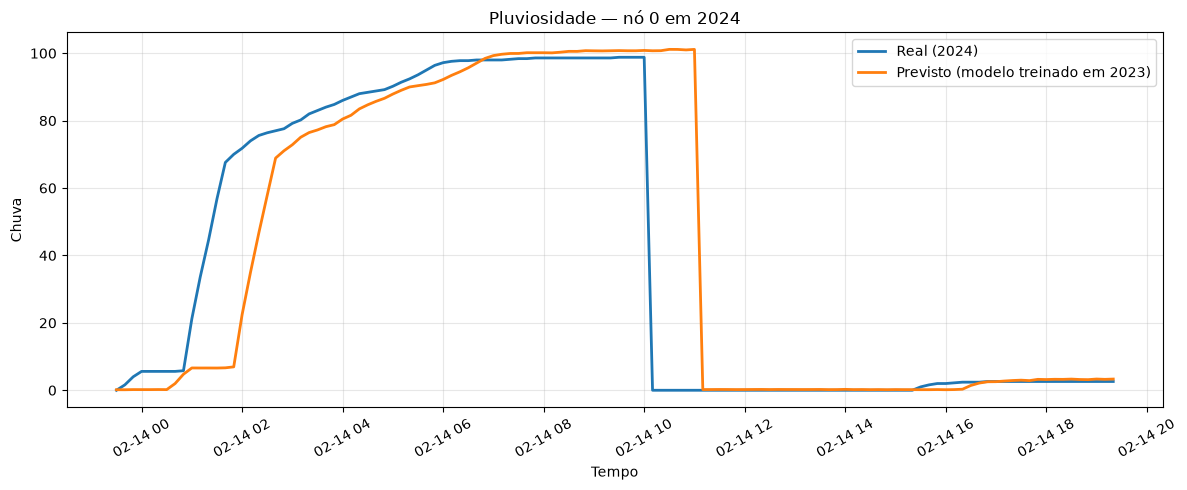

Nó 0 | Pluviosidade | MAE = 0.589571 | RMSE = 3.387807


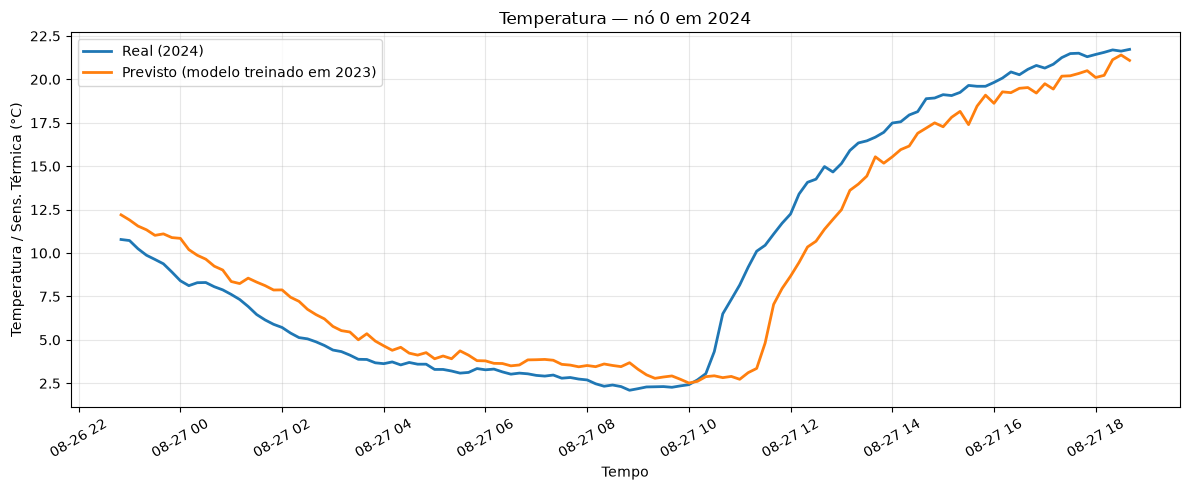

Nó 0 | Temperatura | MAE = 1.137208 | RMSE = 1.620179


In [18]:
def plotar_no_especifico(preds_all, trues_all, timestamps_2024, node_id, nome_variavel, ylabel, criterio_janela="pico_real", window=120):
    preds_no = preds_all[:, node_id]
    trues_no = trues_all[:, node_id]
    half_window = window // 2

    if criterio_janela == "pico_real":
        idx_central = int(np.argmax(trues_no))
    else:
        idx_central = int(np.argmax(np.abs(trues_no - np.mean(trues_no))))

    start = max(0, idx_central - half_window)
    end = min(len(trues_no), idx_central + half_window)
    tempo_2024 = np.array(timestamps_2024[HORIZON:])

    mae = float(np.mean(np.abs(preds_no - trues_no)))
    rmse = float(np.sqrt(np.mean((preds_no - trues_no) ** 2)))

    plt.figure(figsize=(12, 5))
    plt.plot(tempo_2024[start:end], trues_no[start:end], linewidth=2, label="Real (2024)")
    plt.plot(tempo_2024[start:end], preds_no[start:end], linewidth=2, label="Previsto (modelo treinado em 2023)")
    plt.xlabel("Tempo")
    plt.ylabel(ylabel)
    plt.title(f"{nome_variavel} — nó {node_id} em 2024")
    plt.legend()
    plt.xticks(rotation=30)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    plt.close()

    print(f"Nó {node_id} | {nome_variavel} | MAE = {mae:.6f} | RMSE = {rmse:.6f}")

# exemplo:
plotar_no_especifico(preds_chuva_all, trues_chuva_all, timestamps_2024, node_id=0, nome_variavel="Pluviosidade", ylabel="Chuva")
plotar_no_especifico(preds_temp_all, trues_temp_all, timestamps_2024, node_id=0, nome_variavel="Temperatura", ylabel="Temperatura / Sens. Térmica (°C)", criterio_janela="maior_desvio_media")


In [19]:
def obter_indice_no(node_ref, nodes_lista=nodes_lista):
    node_ref_str = str(node_ref)
    nodes_str = [str(n) for n in nodes_lista]

    if node_ref_str in nodes_str:
        return nodes_str.index(node_ref_str)

    if isinstance(node_ref, int) and 0 <= node_ref < len(nodes_lista):
        return node_ref

    raise KeyError(f"Nó {node_ref} não encontrado em nodes_lista.")


def plotar_no_mes(
    preds_all,
    trues_all,
    timestamps,
    node_ref,
    nome_variavel,
    ylabel,
    ano=2024,
    mes=1,
    titulo_real="Referência do experimento cego (média simples dos vizinhos)",
    titulo_prev="Previsto pelo modelo"
):
    node_idx = obter_indice_no(node_ref)
    node_label = G.nodes[str(nodes_lista[node_idx])].get("label", "")

    preds_no = preds_all[:, node_idx]
    trues_no = trues_all[:, node_idx]
    tempo = pd.to_datetime(timestamps[HORIZON:])

    mask = (tempo.year == ano) & (tempo.month == mes)
    tempo_mes = tempo[mask]
    preds_mes = preds_no[mask]
    trues_mes = trues_no[mask]

    print(f"Nó {node_ref} ({node_label}) | pontos encontrados em {mes:02d}/{ano}: {len(tempo_mes)}")

    if len(tempo_mes) == 0:
        print("Nenhum dado encontrado.")
        return

    mae = float(np.mean(np.abs(preds_mes - trues_mes)))
    rmse = float(np.sqrt(np.mean((preds_mes - trues_mes) ** 2)))

    plt.figure(figsize=(15, 5))
    plt.plot(tempo_mes, trues_mes, linewidth=2, label=titulo_real)
    plt.plot(tempo_mes, preds_mes, linewidth=2, linestyle="--", label=titulo_prev)
    plt.xlabel("Tempo")
    plt.ylabel(ylabel)
    plt.title(f"{nome_variavel} — Nó {node_ref} ({node_label}) — {mes:02d}/{ano}")
    plt.legend()
    plt.xticks(rotation=30)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    plt.close()

    print(f"MAE  = {mae:.6f}")
    print(f"RMSE = {rmse:.6f}")


def plotar_nos_cegos_janeiro(
    nos_cegos=("33", "34", "35"),
    ano=2024,
    mes=1
):
    for node_ref in nos_cegos:
        plotar_no_mes(
            preds_all=preds_chuva_all,
            trues_all=trues_chuva_all,
            timestamps=timestamps_2024,
            node_ref=node_ref,
            nome_variavel="Pluviosidade",
            ylabel="Chuva (mm)",
            ano=ano,
            mes=mes
        )
        plotar_no_mes(
            preds_all=preds_temp_all,
            trues_all=trues_temp_all,
            timestamps=timestamps_2024,
            node_ref=node_ref,
            nome_variavel="Temperatura",
            ylabel="Temperatura / Sens. Térmica (°C)",
            ano=ano,
            mes=mes
        )


Nó 33 (IAG-USP) | pontos encontrados em 01/2024: 4458


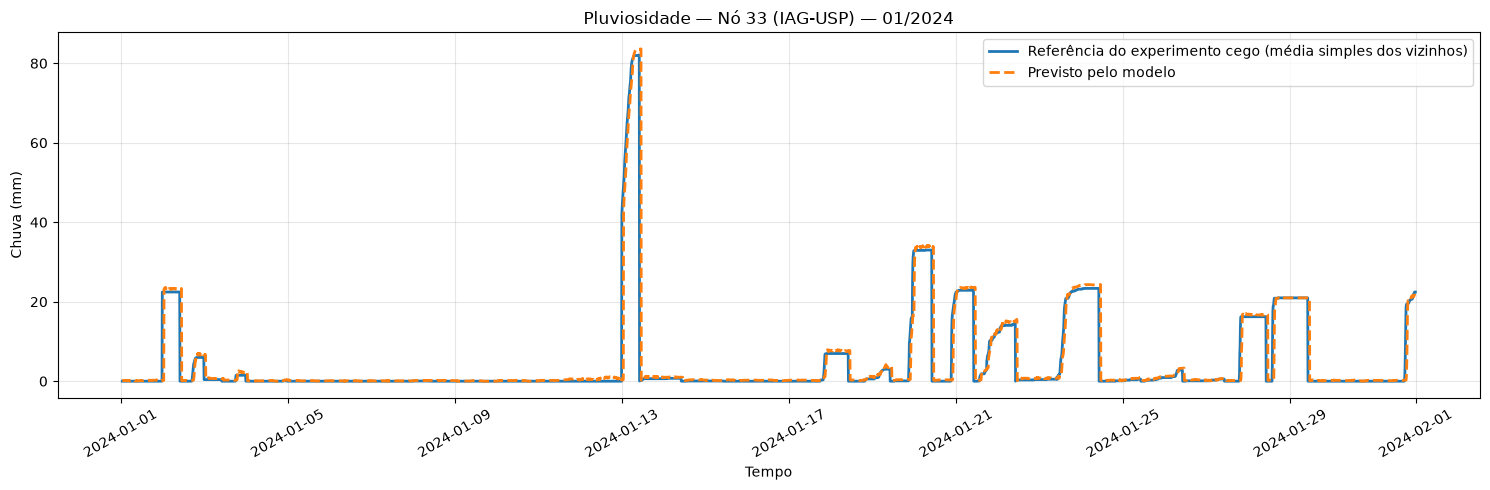

MAE  = 0.944701
RMSE = 4.506767
Nó 33 (IAG-USP) | pontos encontrados em 01/2024: 4458


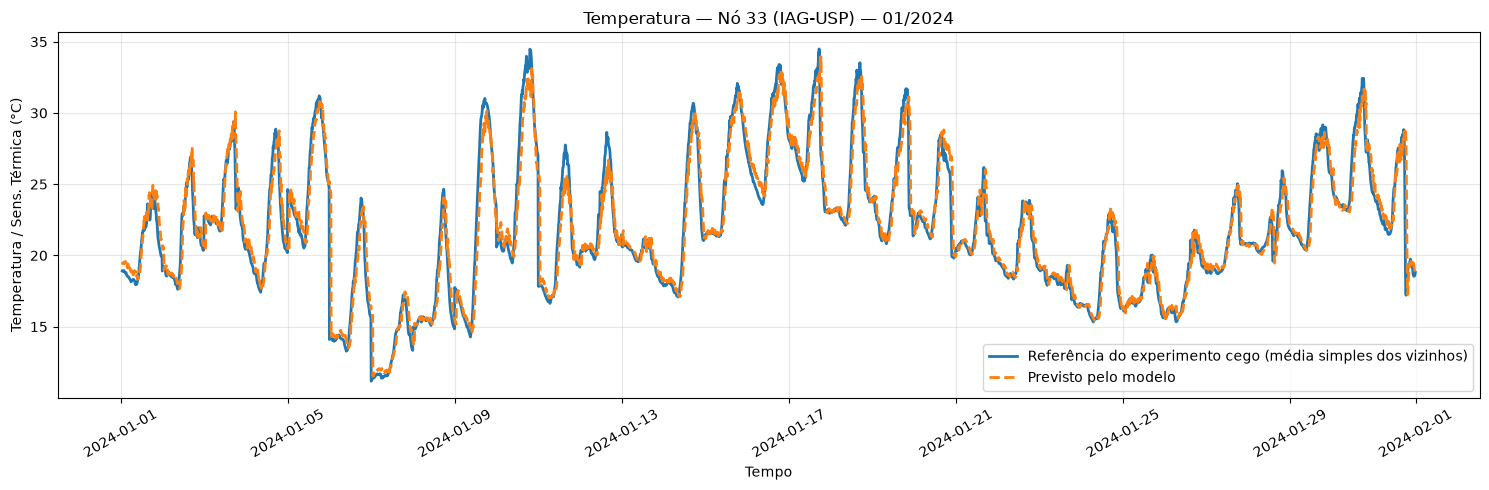

MAE  = 0.793152
RMSE = 1.234659
Nó 34 (INMET - Interlagos) | pontos encontrados em 01/2024: 4458


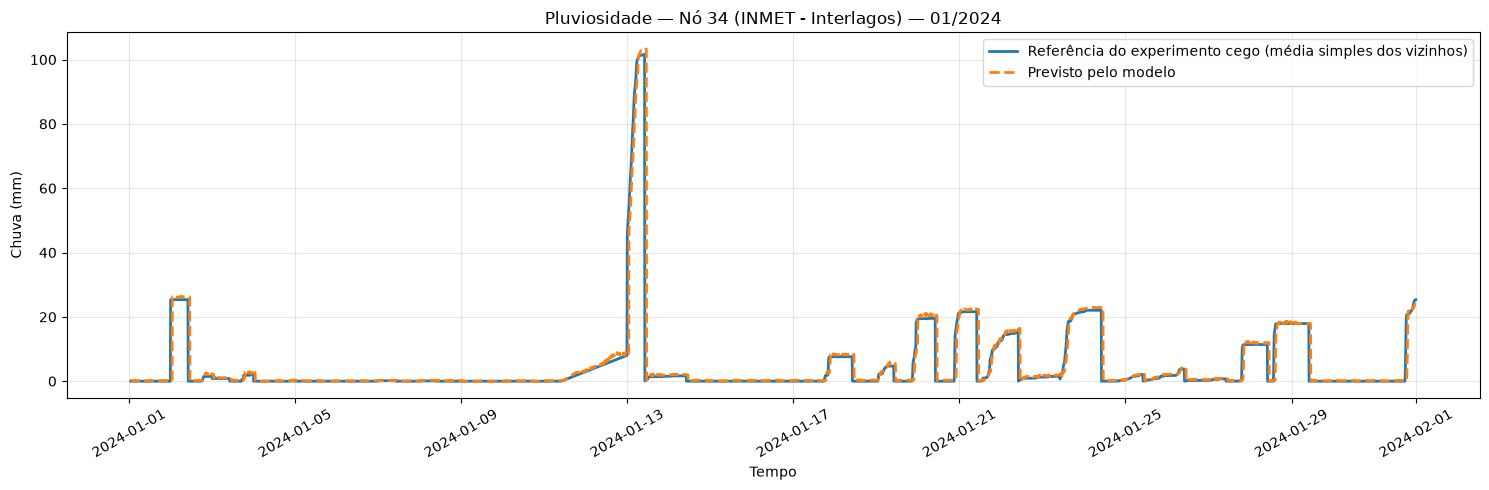

MAE  = 0.935439
RMSE = 4.837217
Nó 34 (INMET - Interlagos) | pontos encontrados em 01/2024: 4458


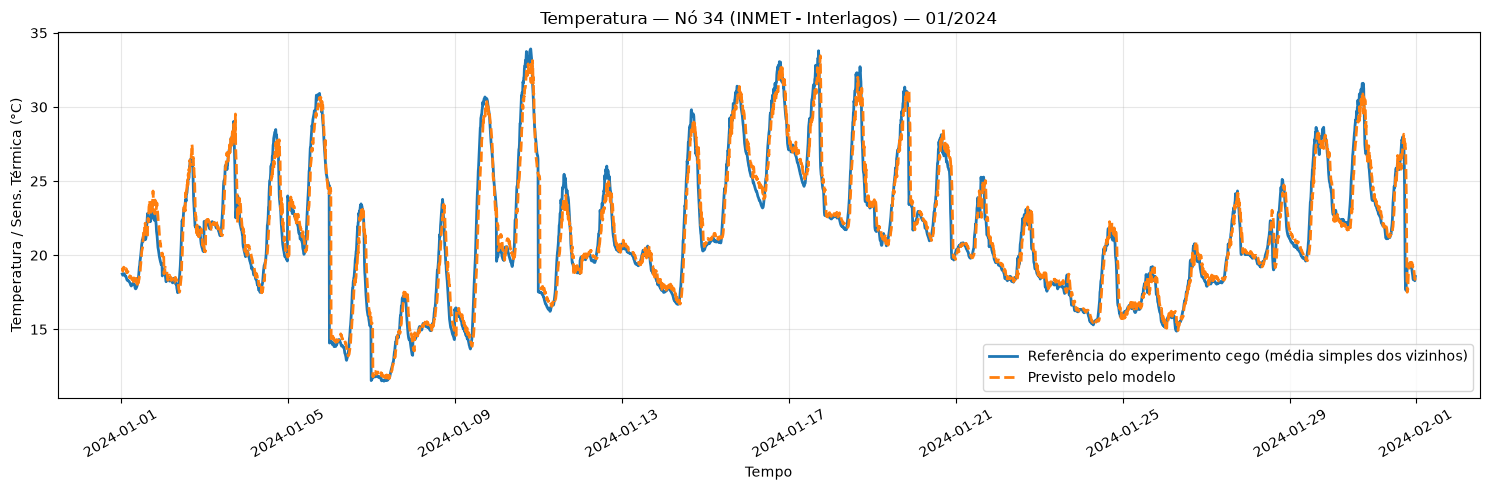

MAE  = 0.732627
RMSE = 1.140587
Nó 35 (INMET - Convencional (Mirante de Santana)) | pontos encontrados em 01/2024: 4458


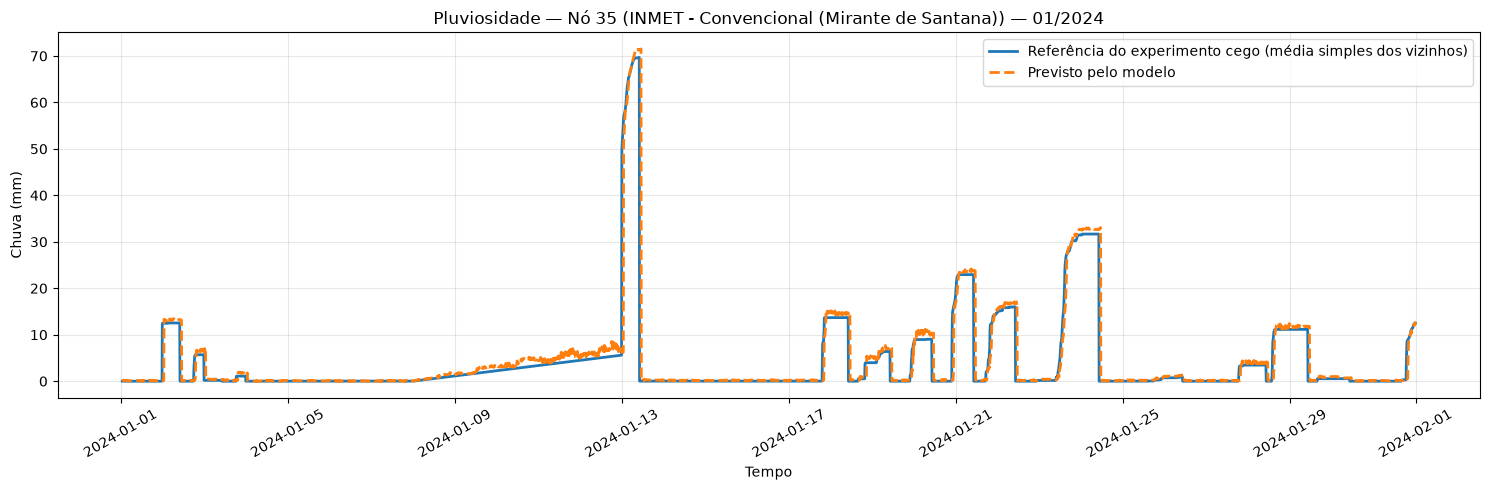

MAE  = 0.918902
RMSE = 3.853951
Nó 35 (INMET - Convencional (Mirante de Santana)) | pontos encontrados em 01/2024: 4458


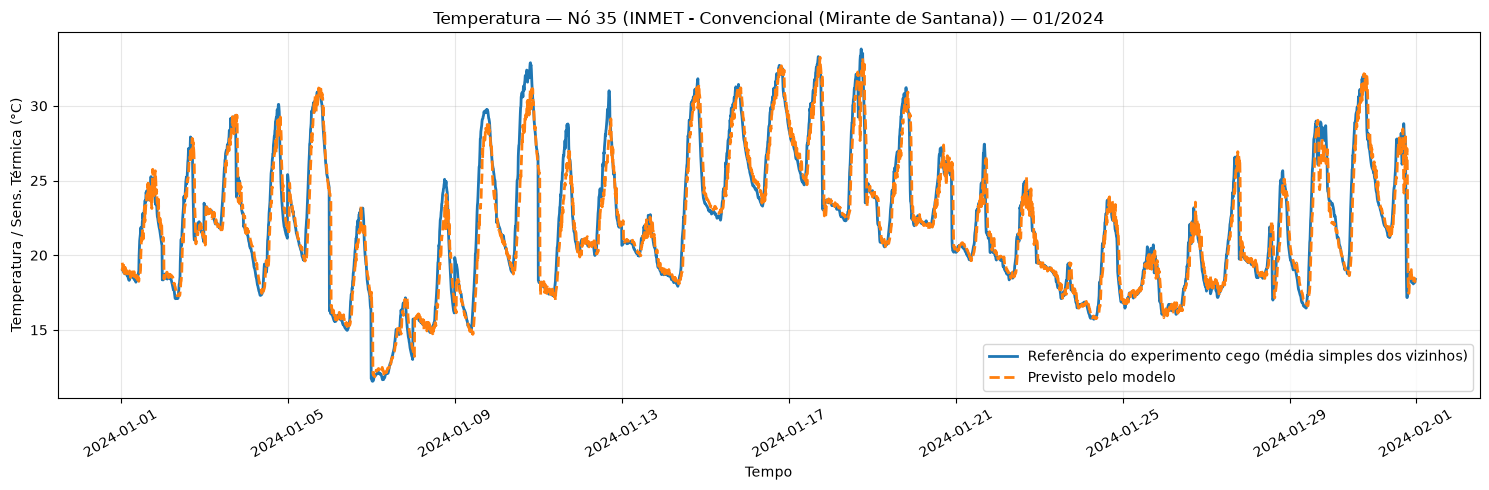

MAE  = 0.831841
RMSE = 1.319735


In [20]:
plotar_nos_cegos_janeiro()


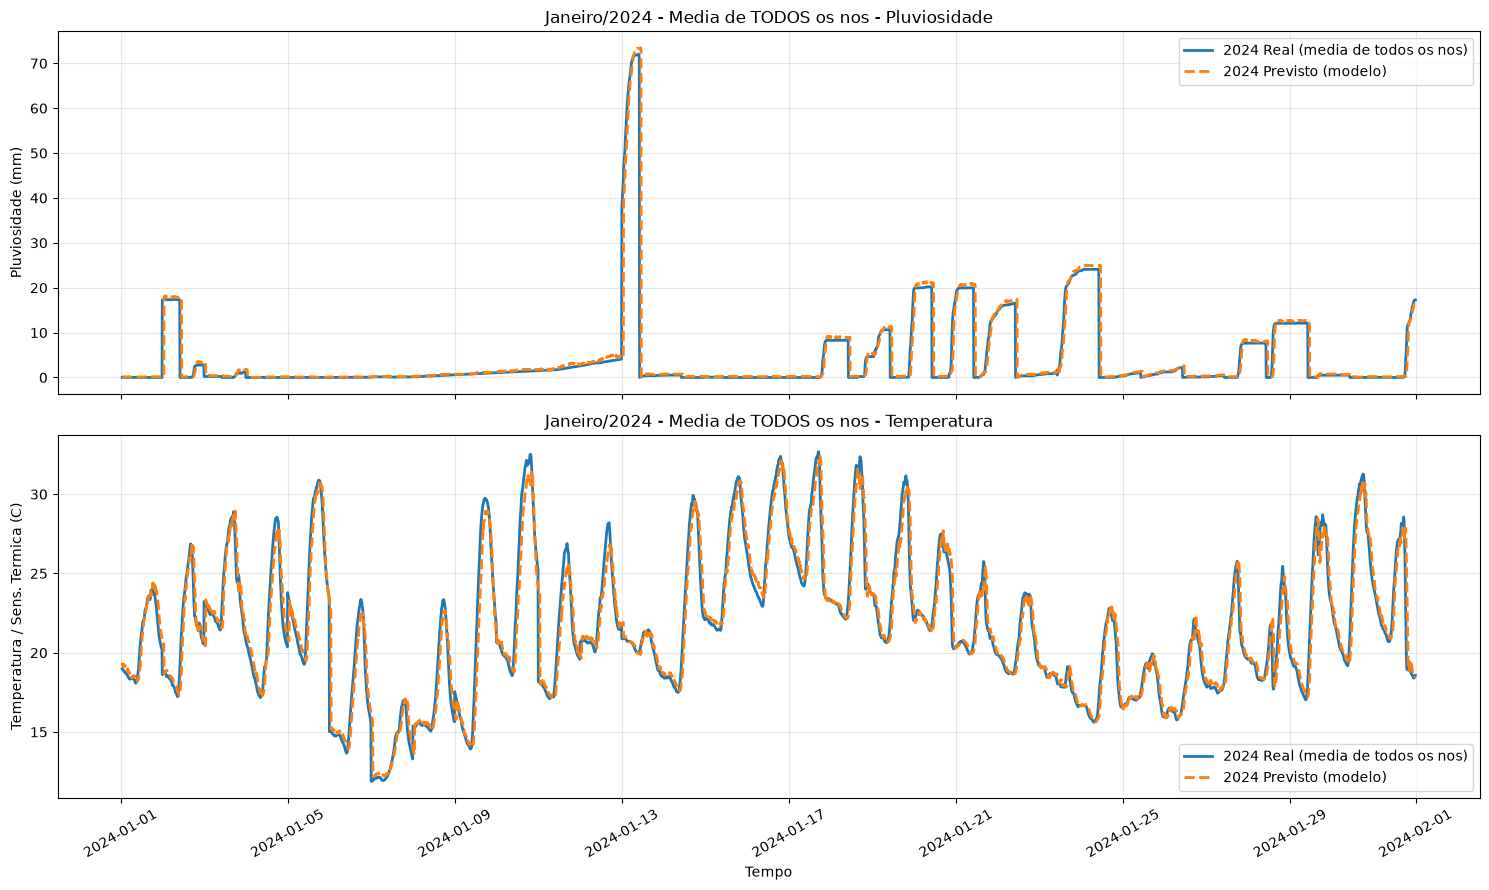


Metricas - Media de TODOS os nos em janeiro/2024
Pluviosidade | MAE = 0.808230 | RMSE = 3.713674
Temperatura  | MAE = 0.699692 | RMSE = 1.030941


In [21]:
def plotar_media_todos_nos_janeiro_2024(
    preds_chuva_all,
    trues_chuva_all,
    preds_temp_all,
    trues_temp_all,
    timestamps_2024
):
    tempo = pd.to_datetime(timestamps_2024[HORIZON:])
    mask_jan_2024 = (tempo.year == 2024) & (tempo.month == 1)

    if mask_jan_2024.sum() == 0:
        print("Nenhum ponto encontrado para janeiro de 2024.")
        return

    tempo_jan = tempo[mask_jan_2024]

    media_real_chuva = trues_chuva_all.mean(axis=1)[mask_jan_2024]
    media_prev_chuva = preds_chuva_all.mean(axis=1)[mask_jan_2024]

    media_real_temp = trues_temp_all.mean(axis=1)[mask_jan_2024]
    media_prev_temp = preds_temp_all.mean(axis=1)[mask_jan_2024]

    mae_chuva = float(np.mean(np.abs(media_prev_chuva - media_real_chuva)))
    rmse_chuva = float(np.sqrt(np.mean((media_prev_chuva - media_real_chuva) ** 2)))

    mae_temp = float(np.mean(np.abs(media_prev_temp - media_real_temp)))
    rmse_temp = float(np.sqrt(np.mean((media_prev_temp - media_real_temp) ** 2)))

    fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

    axes[0].plot(tempo_jan, media_real_chuva, linewidth=2, label="2024 Real (media de todos os nos)")
    axes[0].plot(tempo_jan, media_prev_chuva, linewidth=2, linestyle="--", label="2024 Previsto (modelo)")
    axes[0].set_ylabel("Pluviosidade (mm)")
    axes[0].set_title("Janeiro/2024 - Media de TODOS os nos - Pluviosidade")
    axes[0].grid(alpha=0.3)
    axes[0].legend()

    axes[1].plot(tempo_jan, media_real_temp, linewidth=2, label="2024 Real (media de todos os nos)")
    axes[1].plot(tempo_jan, media_prev_temp, linewidth=2, linestyle="--", label="2024 Previsto (modelo)")
    axes[1].set_xlabel("Tempo")
    axes[1].set_ylabel("Temperatura / Sens. Termica (C)")
    axes[1].set_title("Janeiro/2024 - Media de TODOS os nos - Temperatura")
    axes[1].grid(alpha=0.3)
    axes[1].legend()

    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()
    plt.close()

    print("\nMetricas - Media de TODOS os nos em janeiro/2024")
    print(f"Pluviosidade | MAE = {mae_chuva:.6f} | RMSE = {rmse_chuva:.6f}")
    print(f"Temperatura  | MAE = {mae_temp:.6f} | RMSE = {rmse_temp:.6f}")


plotar_media_todos_nos_janeiro_2024(
    preds_chuva_all=preds_chuva_all,
    trues_chuva_all=trues_chuva_all,
    preds_temp_all=preds_temp_all,
    trues_temp_all=trues_temp_all,
    timestamps_2024=timestamps_2024
)


## Mudança 3 — Identificação de anomalias

Duas regras complementares aplicadas às previsões $\hat{x}_{t+h}$ e aos erros
de previsão:

- **Regra 1 — Limiar meteorológico previsto (alerta antecipado).**
  Pré-computamos $\tau_{i,m,k}$ = percentil 95 por estação $i$, mês $m$ e
  variável $k$. Dispara alerta quando $\hat{x}_{i,k} > \tau_{i,m,k}$.
  Uma **janela anti-ruído** ($W_{alert}=3$) só confirma o alerta após 3
  ativações consecutivas, evitando alarmes falsos por *spikes* de sensor.

- **Regra 2 — Anomaly Score multivariado (distância de Mahalanobis).**
  $AS_{i,t+h} = \sqrt{e^\top \Sigma_i^{-1} e}$, com
  $e = x_{i,t+h} - \hat{x}_{i,t+h}$ (erro após observação) e $\Sigma_i$ a
  covariância histórica das variáveis na estação $i$.


In [22]:
N_NODES = len(nodes_lista)
N_FEATS = X_2024.shape[2]

FEATURE_NAMES = ["PLU", "Temp", "Umid.Rel.", "Vel.VT"][:N_FEATS]
W_ALERT = 3  # janela anti-ruído: nº de timesteps consecutivos p/ confirmar alerta


# ── Regra 1: limiares por estação, mês e variável ────────────────────────────
def compute_thresholds(X_historical, timestamps, percentile=95):
    """Percentil por (mês, nó, variável). Retorna tau [12, N, F]."""
    X_np = X_historical.detach().cpu().numpy() if torch.is_tensor(X_historical) else np.asarray(X_historical)
    N, Fd = X_np.shape[1], X_np.shape[2]
    months = np.array([t.month for t in pd.to_datetime(list(timestamps))])
    tau = np.zeros((12, N, Fd), dtype=np.float64)
    for m in range(12):
        mask = months == (m + 1)
        if mask.sum() == 0:
            tau[m] = np.percentile(X_np, percentile, axis=0)  # fallback global
        else:
            tau[m] = np.percentile(X_np[mask], percentile, axis=0)
    return tau


def rule1_alert(X_hat, tau, month):
    """X_hat [N, F]; month 1..12. Retorna máscara booleana [N, F]."""
    return X_hat > tau[month - 1]


def aplicar_janela_antiruido(alert_series, w_alert=W_ALERT):
    """alert_series: array booleano [T, N, F]. Confirma alerta apenas após
    w_alert ativações consecutivas da Regra 1. Retorna [T, N, F] booleano."""
    alert_series = np.asarray(alert_series, dtype=bool)
    T = alert_series.shape[0]
    confirmado = np.zeros_like(alert_series)
    run = np.zeros(alert_series.shape[1:], dtype=int)
    for t in range(T):
        run = np.where(alert_series[t], run + 1, 0)
        confirmado[t] = run >= w_alert
    return confirmado


# ── Regra 2: anomaly score (Mahalanobis) ─────────────────────────────────────
def compute_sigma_inv(X_historical):
    """Covariância histórica por estação. Retorna sigma_inv [N, F, F]."""
    X_np = X_historical.detach().cpu().numpy() if torch.is_tensor(X_historical) else np.asarray(X_historical)
    N, Fd = X_np.shape[1], X_np.shape[2]
    sigma_inv = np.zeros((N, Fd, Fd), dtype=np.float64)
    for i in range(N):
        xi = X_np[:, i, :]
        if Fd == 1:
            var = np.var(xi[:, 0])
            sigma_inv[i] = np.array([[1.0 / var]]) if var > 1e-12 else np.array([[0.0]])
        else:
            cov = np.cov(xi.T)
            sigma_inv[i] = np.linalg.pinv(cov)
    return sigma_inv


def compute_anomaly_score(x_real, x_hat, sigma_inv):
    """x_real, x_hat: [N, F]; sigma_inv: [N, F, F]. Retorna AS [N]."""
    e = x_real - x_hat
    return torch.einsum("nf,nfg,ng->n", e, sigma_inv, e).clamp(min=0).sqrt()


# ── Cálculo dos artefatos de anomalia ────────────────────────────────────────
# Limiares e covariâncias estimados sobre o histórico (2023).
tau = compute_thresholds(X_hist, timestamps_hist, percentile=95)
sigma_inv = compute_sigma_inv(X_hist)
print("tau:", tau.shape, "| sigma_inv:", sigma_inv.shape)

# Previsões multivariadas no conjunto de teste (2024): usamos os dois modelos
# treinados (PLU e Temp). Demais variáveis assumem persistência da entrada.
modelo.eval(); modelo_temp.eval()
sigma_inv_t = torch.tensor(sigma_inv, dtype=torch.float32, device=DEVICE)

# Previsões absolutas reconstruídas do resíduo (grafos disjuntos), PLU e Temp.
pred_plu_all = prever_absoluto(modelo, g_pyg, X_test, TARGET_IDX_PLU, clip_min=0.0).to(DEVICE)   # [T, N]
pred_temp_all = prever_absoluto(modelo_temp, g_pyg, X_test, TARGET_IDX_TEMP).to(DEVICE)          # [T, N]
X_hat_mv = X_test.clone()
X_hat_mv[:, :, TARGET_IDX_PLU] = pred_plu_all
X_hat_mv[:, :, TARGET_IDX_TEMP] = pred_temp_all

# Real correspondente em t+1.
X_real_next = X_2024[HORIZON:]  # [T-1, N, F]

# Regra 1 sobre as previsões (por mês de cada timestep).
meses_test = np.array([t.month for t in pd.to_datetime(list(timestamps_2024))[HORIZON:]])
alert_raw = np.zeros((len(X_hat_mv), N_NODES, N_FEATS), dtype=bool)
xhat_np = X_hat_mv.detach().cpu().numpy()
for t in range(len(X_hat_mv)):
    alert_raw[t] = rule1_alert(xhat_np[t], tau, int(meses_test[t]))
alert_confirmado = aplicar_janela_antiruido(alert_raw, W_ALERT)
print(f"Regra 1: {alert_raw.sum()} ativações brutas -> "
      f"{alert_confirmado.sum()} confirmadas (janela W={W_ALERT}).")

# Regra 2: anomaly score por timestep e nó.
anomaly_scores = np.zeros((len(X_hat_mv), N_NODES), dtype=np.float64)
with torch.no_grad():
    for t in range(len(X_hat_mv)):
        anomaly_scores[t] = compute_anomaly_score(
            X_real_next[t], X_hat_mv[t], sigma_inv_t
        ).detach().cpu().numpy()
print("anomaly_scores:", anomaly_scores.shape,
      "| AS médio:", float(np.nanmean(anomaly_scores)))

# Tabela consolidada de alertas (Regra 1 confirmada).
linhas_alerta = []
tempo_test = pd.to_datetime(list(timestamps_2024))[HORIZON:]
ts_idx, no_idx, ft_idx = np.where(alert_confirmado)
for t, n, fdim in zip(ts_idx, no_idx, ft_idx):
    linhas_alerta.append({
        "Estacao": str(nodes_lista[n]),
        "Variavel": FEATURE_NAMES[fdim],
        "Tipo": "Regra 1 (limiar previsto)",
        "AS_Score": float(anomaly_scores[t, n]),
        "Timestamp": tempo_test[t],
    })
df_alertas = pd.DataFrame(linhas_alerta)
print(f"\nTotal de alertas confirmados: {len(df_alertas)}")
if len(df_alertas):
    display(df_alertas.sort_values("AS_Score", ascending=False).head(15))


tau: (12, 35, 4) | sigma_inv: (35, 4, 4)


Regra 1: 396351 ativações brutas -> 312440 confirmadas (janela W=3).


anomaly_scores: (52698, 35) | AS médio: 0.739739378942372



Total de alertas confirmados: 312440


,Estacao,Variavel,Tipo,AS_Score,Timestamp
7126,14,PLU,Regra 1 (limiar previsto),42.879517,2024-01-13 10:10:00
7170,14,PLU,Regra 1 (limiar previsto),42.854805,2024-01-13 10:20:00
7214,14,PLU,Regra 1 (limiar previsto),42.779835,2024-01-13 10:30:00
7259,14,PLU,Regra 1 (limiar previsto),42.777554,2024-01-13 10:40:00
7304,14,PLU,Regra 1 (limiar previsto),42.759109,2024-01-13 10:50:00
7349,14,PLU,Regra 1 (limiar previsto),42.715134,2024-01-13 11:00:00
7320,28,PLU,Regra 1 (limiar previsto),25.006096,2024-01-13 10:50:00
7186,28,PLU,Regra 1 (limiar previsto),25.004435,2024-01-13 10:20:00
7275,28,PLU,Regra 1 (limiar previsto),25.004225,2024-01-13 10:40:00
7230,28,PLU,Regra 1 (limiar previsto),25.003984,2024-01-13 10:30:00


## Métricas: baseline (média simples dos vizinhos) vs FP + GraphSAGE (nós cegos)

Compara, nos nós cegos, a estimativa antiga (média simples dos vizinhos) com a
nova (Feature Propagation + GraphSAGE), em MAE/RMSE por variável.


In [23]:
def mae_rmse(real, est):
    real = np.asarray(real); est = np.asarray(est)
    mae = float(np.mean(np.abs(est - real)))
    rmse = float(np.sqrt(np.mean((est - real) ** 2)))
    return mae, rmse

linhas = []
X2024_np = X_2024.detach().cpu().numpy()
X2024_base_np = X_2024_baseline.detach().cpu().numpy()
for j in blind_idx:
    nome = str(nodes_lista[j])
    for fdim, fname in enumerate(FEATURE_NAMES):
        # "real" de referência para nós cegos = valor FP (não há observação direta);
        # comparamos a entrada baseline com a entrada FP por variável.
        mae_b, rmse_b = mae_rmse(X2024_np[:, j, fdim], X2024_base_np[:, j, fdim])
        linhas.append({
            "No": nome, "Variavel": fname,
            "MAE_baseline_vs_FP": mae_b, "RMSE_baseline_vs_FP": rmse_b,
        })
df_metricas_cegos = pd.DataFrame(linhas)
print("Diferença entre inicialização baseline e Feature Propagation (nós cegos):")
display(df_metricas_cegos)

# Métrica global de previsão (FP + GraphSAGE) por variável no teste.
resumo_pred = pd.DataFrame([
    {"Variavel": "Pluviosidade",
     "MAE": float(df_resultados_chuva["mae"].mean()),
     "RMSE": float(df_resultados_chuva["rmse"].mean())},
    {"Variavel": "Temperatura",
     "MAE": float(df_resultados_temp["mae"].mean()),
     "RMSE": float(df_resultados_temp["rmse"].mean())},
])
print("\nMétricas médias de previsão (FP + GraphSAGE) no teste 2024:")
display(resumo_pred)


Diferença entre inicialização baseline e Feature Propagation (nós cegos):


,No,Variavel,MAE_baseline_vs_FP,RMSE_baseline_vs_FP
0,33,PLU,0.100683,0.389694
1,33,Temp,0.063762,0.110303
2,33,Umid.Rel.,0.769002,1.090381
3,33,Vel.VT,0.064581,0.086105
4,34,PLU,0.226109,0.808132
5,34,Temp,0.187487,0.242248
6,34,Umid.Rel.,0.721550,1.214669
7,34,Vel.VT,0.139215,0.185866
8,35,PLU,0.693983,1.781161
9,35,Temp,0.502193,0.725511



Métricas médias de previsão (FP + GraphSAGE) no teste 2024:


,Variavel,MAE,RMSE
0,Pluviosidade,0.539258,2.845912
1,Temperatura,0.878242,1.322688


## Exportação de artefatos para o dashboard

Salva em `artifacts/` tudo o que o `dashboard.py` (Streamlit) precisa para
simular o monitoramento: pesos dos modelos, limiares, covariâncias inversas,
estrutura do grafo, e os tensores/previsões de teste.


In [24]:
import pickle

os.makedirs(ARTIFACTS_DIR, exist_ok=True)

# 1) Pesos dos modelos.
torch.save(modelo.state_dict(), os.path.join(ARTIFACTS_DIR, "model_plu.pt"))
torch.save(modelo_temp.state_dict(), os.path.join(ARTIFACTS_DIR, "model_temp.pt"))

# 2) Limiares tau [12, N, F].
with open(os.path.join(ARTIFACTS_DIR, "tau.pkl"), "wb") as f:
    pickle.dump(tau, f)

# 3) Inversas de covariância [N, F, F].
with open(os.path.join(ARTIFACTS_DIR, "sigma_inv.pkl"), "wb") as f:
    pickle.dump(sigma_inv, f)

# 4) Estrutura do grafo: edge_index, edge_weight, coords, nomes.
coords = {}
labels = {}
for n in nodes_lista:
    ns = str(n)
    coords[ns] = (float(G.nodes[ns].get("lat", 0.0)), float(G.nodes[ns].get("lon", 0.0)))
    labels[ns] = str(G.nodes[ns].get("label", ns))

graph_data = {
    "edge_index": g_pyg.edge_index.detach().cpu().numpy(),
    "edge_weight": g_pyg.edge_weight.detach().cpu().numpy(),
    "edge_weight_sym": g_pyg.edge_weight_sym.detach().cpu().numpy(),
    "nodes_lista": [str(n) for n in nodes_lista],
    "coords": coords,
    "labels": labels,
    "blind_nodes": sorted(NOS_SEM_DADOS),
    "feature_names": FEATURE_NAMES,
    "target_idx_plu": TARGET_IDX_PLU,
    "target_idx_temp": TARGET_IDX_TEMP,
    "model_h_feats": 64,
}
with open(os.path.join(ARTIFACTS_DIR, "graph_data.pkl"), "wb") as f:
    pickle.dump(graph_data, f)

# 5) Tensores de teste + previsões + alertas + score, para simular monitoramento.
X_test_export = {
    "X_2024": X_2024.detach().cpu().numpy(),              # [T, N, F] (com FP)
    "X_2024_baseline": X_2024_baseline.detach().cpu().numpy(),  # baseline média vizinhos
    "timestamps_2024": [pd.Timestamp(t).isoformat() for t in timestamps_2024],
    "X_hat_mv": X_hat_mv.detach().cpu().numpy(),          # previsões [T-1, N, F]
    "X_real_next": X_real_next.detach().cpu().numpy(),    # real em t+1 [T-1, N, F]
    "alert_confirmado": alert_confirmado,                 # [T-1, N, F] bool
    "anomaly_scores": anomaly_scores,                     # [T-1, N]
    "preds_chuva_all": preds_chuva_all,
    "trues_chuva_all": trues_chuva_all,
    "preds_temp_all": preds_temp_all,
    "trues_temp_all": trues_temp_all,
    "df_alertas": df_alertas,
    "df_resultados_chuva": df_resultados_chuva,
    "df_resultados_temp": df_resultados_temp,
    "df_metricas_cegos": df_metricas_cegos,
    "resumo_pred": resumo_pred,
}
with open(os.path.join(ARTIFACTS_DIR, "X_test.pkl"), "wb") as f:
    pickle.dump(X_test_export, f)

print("Artefatos salvos em", os.path.abspath(ARTIFACTS_DIR))
for fn in sorted(os.listdir(ARTIFACTS_DIR)):
    print("  -", fn)


Artefatos salvos em /home/viniz0r/backup_GNN_2026-07-07/paper_essenciais/codigo/artifacts
  - X_test.pkl
  - X_test_traintrain.pkl
  - X_test_valsplit.pkl
  - ablacao.json
  - ablacao_valsplit.json
  - fp_mascaramento.json
  - fp_mascaramento_krig.json
  - graph_data.pkl
  - model_plu.pt
  - model_temp.pt
  - peryear_cache.pt
  - sigma_inv.pkl
  - stgcn_valsplit.json
  - tau.pkl
  - train_cache.pt
